# Processamento de imagens de SEM - Segmentação, detecção, textura e orientação
### Partículas, grãos e poros: tamanhos, forma, distribuição espacial e orientação (adaptado do fluxo de identificação de fases e mapeamento de orientação)

## Como usar

Este notebook foi adaptado do fluxo original de **4D-STEM** (identificação de fases e mapeamento de orientação, ACOM) para **imagens de microscopia eletrônica de varredura (SEM) 2D**. O foco é **detectar, medir e mapear** partículas, grãos ou poros, e quantificar a microestrutura.

**Etapas do fluxo original e seus equivalentes em SEM**

| Fluxo original (4D-STEM) | Equivalente neste notebook (imagem SEM) |
|---|---|
| Correção de flatfield e pixels quentes | Remoção da faixa de dados, correção do ruído de linha, pixels quentes e sombreamento |
| Padrão de difração médio | Espectro de potência (FFT) da imagem |
| Raio da sonda e calibração | Raio típico dos objetos (espaço-escala) e calibração (metadados, barra de escala ou manual) |
| Imagens virtuais BF / ADF | Imagens virtuais no espaço real: média em disco (BF) e em anel (ADF) |
| Sonda de vácuo e kernel | Template construído com objetos isolados e kernel de média zero |
| Detecção dos discos de Bragg | Detecção por correlação cruzada com o mesmo conjunto de parâmetros |
| Origem do feixe e ajuste de plano | Refinamento dos centros por centro de massa e ajuste de plano ao fundo local |
| Mapa de vetores de Bragg e integral radial | Mapa de vetores entre pares e função de distribuição radial g(r) com envelope aleatório |
| Plano de orientação e mapas ACOM | Biblioteca de elipses: mapas de orientação, razão de aspecto e qualidade do ajuste |
| Mapas de deformação (strain) | Mapas do tensor de estrutura local (anisotropia e orientação) |

**Análises paralelas incluídas**

1. **Segmentação e distribuição de tamanhos**: diâmetro equivalente (D10/D50/D90), circularidade, razão de aspecto, fração de área (cobertura ou porosidade) e distribuição acumulada por número e por área.
2. **Estatística espacial**: g(r) com envelope aleatório, vizinho mais próximo (índice de Clark-Evans), células de Voronoi e mapa de densidade local.
3. **Orientação e anisotropia**: orientação dominante, parâmetro de ordem e diagrama polar (estruturas alinhadas, estrias, fibras).
4. **Fases por níveis de cinza** (multi-Otsu) e sensibilidade ao limiar.
5. **Textura** (GLCM) dos objetos e do fundo, rugosidade local e comprimento de correlação (autocorrelação).
6. **Tabela de qualidade** (SNR, nitidez, entropia) das versões da imagem.

**Passos**

1. Coloque este notebook e a imagem de SEM (`.tif`, `.png`, `.jpg` ou `.bmp`) **na mesma pasta**. Sem informar nada, o notebook usa a primeira imagem encontrada; para escolher outra, preencha `nome_imagem` na célula de caminhos.
2. Execute as células **na ordem, de cima para baixo**.
3. **Calibração**: o tamanho do pixel é lido dos metadados (FEI/Thermo Fisher ou Zeiss), se existirem. Caso contrário, informe `tamanho_pixel_nm` ou o valor escrito na barra de escala em `comprimento_barra_nm` (ex.: 1000 para "1 µm"). Sem calibração, tudo é mostrado em pixels.
4. Defina `tipo_objeto` (`'claro'` para partículas ou grãos mais claros que o fundo; `'escuro'` para poros ou cavidades) e ajuste `raio_min_busca` / `raio_max_busca` ao tamanho dos objetos.
5. Os resultados (imagens `.tif` e tabelas `.csv`) são gravados na mesma pasta, com `_SAIDA_` no nome.
6. O OpenCV (`cv2`) é opcional: sem ele, o notebook usa alternativas do scikit-image.

# Agradecimentos e ressalvas

In [1]:
# Este tutorial foi adaptado da equipe de instrutores do py4DSTEM por Abraham Contreras(guzmanabraham108@gmail.com):

# Georgios Varnavides (gvarnavides@berkeley.edu)
# Stephanie Ribet (sribet@lbl.gov)
# Colin Ophus (clophus@lbl.gov)

# Ele não utiliza todos os recursos do py4DSTEM.
# Não está totalmente otimizado.
# Seu objetivo é mostrar que funciona e que é divertido de usar!
# Para tutoriais completos do py4DSTEM, visite:
# https://github.com/py4dstem/py4DSTEM_tutorials/tree/main/notebooks


In [2]:
# Se o py4DSTEM for útil para o seu trabalho, por favor cite:

# py4DSTEM: A Software Package for Four-Dimensional Scanning Transmission Electron Microscopy Data Analysis 

# Benjamin H Savitzky, Steven E Zeltmann, Lauren A Hughes, Hamish G Brown, Shiteng Zhao, Philipp M Pelz, Thomas C Pekin,
# Edward S Barnard, Jennifer Donohue, Luis Rangel DaCosta, Ellis Kennedy, Yujun Xie, Matthew T Janish, Matthew M Schneider, 
# Patrick Herring, Chirranjeevi Gopal, Abraham Anapolsky, Rohan Dhall, Karen C Bustillo, Peter Ercius, Mary C Scott, Jim Ciston, Andrew M Minor, Colin Ophus

# Microscopy and Microanalysis, Volume 27, Issue 4, 1 August 2021, Pages 712–743, 
# https://doi.org/10.1017/S1431927621000477

In [3]:
# Amostra cedida por cortesia de Mingjian Wu, FAU, Alemanha
# Experimento e dados cedidos por cortesia de Mingjian Wu, FAU, Alemanha

# Início

In [4]:
# Definição dos caminhos do conjunto de dados

import os
from pathlib import Path


def obter_pasta_do_notebook():
    """Retorna a pasta onde este arquivo .ipynb está salvo."""

    # VS Code
    arquivo_vscode = globals().get('__vsc_ipynb_file__')
    if arquivo_vscode:
        return Path(arquivo_vscode).resolve().parent

    # JupyterLab / Jupyter Notebook
    sessao = os.environ.get('JPY_SESSION_NAME')
    if sessao and Path(sessao).is_absolute() and Path(sessao).exists():
        return Path(sessao).resolve().parent

    # Execução como script .py
    if '__file__' in globals():
        return Path(__file__).resolve().parent

    # Diretório de trabalho atual
    return Path.cwd().resolve()


# Pasta do notebook: todas as imagens devem estar nesta mesma pasta
pasta_notebook = obter_pasta_do_notebook()
print('Pasta do notebook (e das imagens):', pasta_notebook)

# Pasta (a mesma pasta do notebook, com separador final)
file_path = str(pasta_notebook) + os.sep

# Nome da imagem de SEM. Com None, usa a primeira imagem encontrada na pasta.
# Para analisar outra imagem, informe o nome (ex.: 'amostra_01.tif').
nome_imagem = None

extensoes_imagem = ('.tif', '.tiff', '.png', '.jpg', '.jpeg', '.bmp')
# Arquivos gerados por este notebook contêm '_SAIDA_' e são ignorados na busca; 'FF_*' são flatfields
candidatas = sorted(p.name for p in pasta_notebook.iterdir()
                    if p.suffix.lower() in extensoes_imagem and '_SAIDA_' not in p.name and not p.name.upper().startswith('FF_'))
print('Imagens encontradas na pasta:', candidatas)

if nome_imagem is None:
    if not candidatas:
        raise FileNotFoundError('Nenhuma imagem (' + ', '.join(extensoes_imagem) + ') encontrada em ' + str(pasta_notebook) +
                                '. Coloque a imagem de SEM na mesma pasta deste notebook.')
    nome_imagem = candidatas[0]

filename = file_path + nome_imagem
if not os.path.isfile(filename):
    raise FileNotFoundError('Imagem não encontrada: ' + filename + '. Coloque o arquivo na mesma pasta deste notebook.')
print('Imagem analisada:', nome_imagem)

Pasta do notebook (e das imagens): C:\JupyterLab\2-semestre\IP1\SEM
Imagens encontradas na pasta: ['MEV-NC_AM_BSE_005.tif']
Imagem analisada: MEV-NC_AM_BSE_005.tif


In [5]:
# Importação das bibliotecas

import os
import re
import csv
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import patches
from matplotlib.colors import hsv_to_rgb
from types import SimpleNamespace

import tifffile
import scipy
from scipy import ndimage
from scipy.signal import fftconvolve
from scipy.special import expit
from scipy.spatial import cKDTree, Voronoi
from scipy.spatial.distance import pdist

import skimage
from skimage import exposure, restoration, filters, measure, segmentation, feature

# OpenCV é opcional: acelera a redução de ruído (Non-Local Means) e o CLAHE
try:
    import cv2
except ImportError:
    cv2 = None
    print('Aviso: OpenCV (cv2) não encontrado; serão usadas alternativas do scikit-image.')

# As bibliotecas do fluxo 4D-STEM (py4DSTEM, h5py, hdf5plugin) não são necessárias para imagens de SEM 2D.

# Funções auxiliares
As células a seguir apenas definem funções (não processam a imagem).

In [6]:
# Funções auxiliares (1/4): leitura, calibração, faixa de dados e ruído de varredura

def ler_imagem_sem(caminho):
    """Lê uma imagem de SEM (TIFF, PNG, JPG ou BMP) e devolve uma matriz 2D, preservando o tipo de dado."""
    caminho = str(caminho)
    if caminho.lower().endswith(('.tif', '.tiff')):
        imagem = np.squeeze(tifffile.imread(caminho))
    else:
        from skimage import io as skio
        imagem = np.squeeze(skio.imread(caminho))
    if imagem.ndim == 3 and imagem.shape[-1] in (3, 4):
        # Imagem RGB(A) (comum em exportações): converte para tons de cinza
        imagem = imagem[..., :3].mean(axis=-1).astype(imagem.dtype)
    elif imagem.ndim == 3:
        print('Aviso: o arquivo contém', imagem.shape[0], 'quadros; usando apenas o primeiro.')
        imagem = imagem[0]
    if imagem.ndim != 2:
        raise ValueError('A imagem deve ser bidimensional; forma lida: ' + str(imagem.shape))
    return imagem


def _buscar_chave(obj, nome):
    """Busca recursivamente uma chave em dicionários e listas aninhados."""
    if isinstance(obj, dict):
        for k, v in obj.items():
            if str(k).lower() == nome.lower():
                return v
            r = _buscar_chave(v, nome)
            if r is not None:
                return r
    elif isinstance(obj, (list, tuple)):
        for v in obj:
            r = _buscar_chave(v, nome)
            if r is not None:
                return r
    return None


def _para_nm(valor, unidade):
    """Converte um comprimento para nanômetros."""
    unidade = str(unidade).strip().lower().replace('µ', 'u').replace('μ', 'u')
    fatores = {'m': 1e9, 'mm': 1e6, 'um': 1e3, 'nm': 1.0, 'pm': 1e-3, 'å': 0.1}
    return float(valor) * fatores.get(unidade, np.nan)


def _extrair_valor_unidade(v):
    """Extrai 'número + unidade' de um texto ou de uma lista de campos; devolve nm ou None."""
    itens = list(v) if isinstance(v, (list, tuple)) else [v]
    texto = ' '.join(str(i) for i in itens)
    m = re.search(r'([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)\s*(nm|um|µm|μm|mm|pm|Å|m)(?![a-zA-Z])', texto)
    return _para_nm(m.group(1), m.group(2)) if m else None


def ler_calibracao_metadados(caminho):
    """
    Tenta obter o tamanho do pixel (nm) dos metadados do TIFF (FEI/Thermo Fisher ou Zeiss).
    Devolve (nm por pixel, origem) ou (None, None).
    """
    try:
        with tifffile.TiffFile(str(caminho)) as tif:
            fei = getattr(tif, 'fei_metadata', None)
            if fei:
                v = _buscar_chave(fei, 'PixelWidth')
                if v is not None:
                    return float(v) * 1e9, 'metadados FEI/Thermo Fisher (PixelWidth)'
            sem = getattr(tif, 'sem_metadata', None)
            if sem:
                v = _buscar_chave(sem, 'ap_image_pixel_size')
                nm = _extrair_valor_unidade(v) if v is not None else None
                if nm is not None and np.isfinite(nm):
                    return nm, 'metadados Zeiss (ap_image_pixel_size)'
    except Exception:
        pass
    return None, None


def detectar_faixa_de_dados(imagem, fracao_max=0.30, tolerancia=2, fracao_plana=0.5):
    """
    Procura, no rodapé, a faixa de dados do microscópio (fundo uniforme com texto e barra de escala).
    Devolve {'linha_inicio', 'fundo'} ou None se não houver faixa.
    """
    h, w = imagem.shape
    modo_ref, inicio = None, h
    for r in range(h - 1, int(h * (1 - fracao_max)) - 1, -1):
        valores, contagens = np.unique(imagem[r], return_counts=True)
        modo = int(valores[np.argmax(contagens)])
        plana = float(np.mean(np.abs(imagem[r].astype(np.int64) - modo) <= tolerancia))
        if modo_ref is None:
            modo_ref = modo
        if plana >= fracao_plana and (abs(modo - modo_ref) <= 2 * tolerancia or plana >= 0.95):
            inicio = r
        else:
            break
    if h - inicio < 20:
        return None
    return {'linha_inicio': inicio, 'fundo': modo_ref}


def detectar_barra_de_escala_sem(imagem, faixa, largura_min=30):
    """Maior segmento horizontal contrastante dentro da faixa de dados (a barra de escala). Devolve comprimento em pixels."""
    regiao = imagem[faixa['linha_inicio']:].astype(np.int64)
    if np.issubdtype(imagem.dtype, np.integer):
        limite = 0.25 * float(np.iinfo(imagem.dtype).max)
    else:
        limite = 0.25 * float(imagem.max())
    diferente = np.abs(regiao - faixa['fundo']) > limite
    melhor, linha = 0, None
    for i in range(diferente.shape[0]):
        if not diferente[i].any():
            continue
        dif = np.diff(np.concatenate(([0], diferente[i].astype(np.int8), [0])))
        comprimento = int((np.flatnonzero(dif == -1) - np.flatnonzero(dif == 1)).max())
        if comprimento >= 0.6 * imagem.shape[1]:       # linhas divisórias da faixa não são a barra
            continue
        if comprimento > melhor:
            melhor, linha = comprimento, i
    if melhor < largura_min:
        return None
    return {'comprimento_px': melhor, 'linha': faixa['linha_inicio'] + linha}


def corrigir_listras_de_varredura(imagem, sigma_linhas=12.0, limite_mad=4.0):
    """
    Remove deslocamentos de brilho linha a linha (ruído de varredura típico de SEM).
    Devolve (imagem corrigida, deslocamento de cada linha).
    """
    perfil = np.median(imagem, axis=1)
    suave = ndimage.gaussian_filter1d(perfil, sigma_linhas, mode='nearest')
    desloc = perfil - suave
    mad = 1.4826 * np.median(np.abs(desloc - np.median(desloc)))
    desloc = np.clip(desloc, -limite_mad * max(mad, 1e-6), limite_mad * max(mad, 1e-6))
    return (imagem - desloc[:, None]).astype(np.float32), desloc

In [7]:
# Funções auxiliares (2/4): ruído, correção de fundo, pixels quentes e processamento em etapas

def estimar_ruido(imagem, mascara=None):
    """Desvio padrão do ruído (método robusto baseado no resíduo do laplaciano de 3x3)."""
    nucleo = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float32)
    residuo = ndimage.convolve(imagem.astype(np.float32), nucleo, mode='reflect')
    if mascara is not None:
        residuo = residuo[ndimage.binary_erosion(mascara, iterations=3)]
    mad = np.median(np.abs(residuo - np.median(residuo)))
    return float(1.4826 * mad / 6.0)


def estimar_fundo_polinomial(imagem, mascara_valida, ordem=3, fator=16, n_iter=8, k_baixo=1.5, k_alto=3.0):
    """
    Estima o fundo de iluminação (vinheta/inclinação) ajustando um polinômio 2D em resolução reduzida,
    com rejeição iterativa dos pixels do espécime (mais escuros) e de valores muito claros.
    """
    h, w = imagem.shape
    hb, wb = h // fator, w // fator
    bloco = imagem[:hb * fator, :wb * fator].reshape(hb, fator, wb, fator)
    val = mascara_valida[:hb * fator, :wb * fator].reshape(hb, fator, wb, fator)
    n_val = val.sum(axis=(1, 3))
    media = (bloco * val).sum(axis=(1, 3)) / np.maximum(n_val, 1)
    valido = n_val >= 0.9 * fator * fator

    def termos(yy, xx):
        return [xx ** i * yy ** j for i in range(ordem + 1) for j in range(ordem + 1 - i)]

    yy, xx = np.meshgrid((np.arange(hb) + 0.5) / hb * 2 - 1, (np.arange(wb) + 0.5) / wb * 2 - 1, indexing='ij')
    A = np.stack([t[valido] for t in termos(yy, xx)], axis=1)
    b = media[valido]
    usar = np.ones_like(b, dtype=bool)
    for _ in range(n_iter):
        coef = np.linalg.lstsq(A[usar], b[usar], rcond=None)[0]
        residuo = b - A @ coef
        sigma = 1.4826 * np.median(np.abs(residuo[usar] - np.median(residuo[usar])))
        usar = (residuo > -k_baixo * sigma) & (residuo < k_alto * sigma)
    Y, X = np.meshgrid((np.arange(h) + 0.5) / h * 2 - 1, (np.arange(w) + 0.5) / w * 2 - 1, indexing='ij')
    fundo = sum(c * t for c, t in zip(coef, termos(Y, X)))
    return fundo.astype(np.float32)


def remover_pixels_quentes(imagem, limiar_sigma=6.0, mascara=None):
    """Substitui pixels isolados muito diferentes da mediana 3x3 (raios X, pixels defeituosos)."""
    mediana = ndimage.median_filter(imagem, size=3, mode='reflect')
    residuo = imagem - mediana
    sigma = estimar_ruido(imagem, mascara)
    quentes = np.abs(residuo) > limiar_sigma * max(sigma, 1e-6)
    resultado = imagem.copy()
    resultado[quentes] = mediana[quentes]
    return resultado, int(quentes.sum())


def normalizar_percentis(imagem, percentis=(0.5, 99.7), mascara=None):
    """
    Ajusta a faixa tonal usando percentis.
    Evita que poucos pixels extremos dominem o contraste.
    """
    referencia = imagem if mascara is None else imagem[mascara]
    p_low, p_high = np.percentile(referencia, percentis)
    resultado = (imagem - p_low) / max(p_high - p_low, 1e-8)
    return np.clip(resultado, 0, 1).astype(np.float32)


def reduzir_ruido(imagem, intensidade):
    """
    Redução de ruído Non-Local Means (OpenCV). A operação é realizada em uint8.
    Sem OpenCV, usa variação total (Chambolle) como alternativa.
    """
    imagem_uint8 = np.round(np.clip(imagem, 0, 1) * 255).astype(np.uint8)
    if cv2 is not None:
        resultado = cv2.fastNlMeansDenoising(imagem_uint8, None, h=float(intensidade),
                                             templateWindowSize=7, searchWindowSize=21)
        return resultado.astype(np.float32) / 255.0
    peso = 2.0 * float(intensidade) / 255.0
    return np.clip(restoration.denoise_tv_chambolle(imagem, weight=peso), 0, 1).astype(np.float32)


def aplicar_clahe(imagem, limite, grade):
    """Realce adaptativo de contraste local."""
    imagem_uint8 = np.round(np.clip(imagem, 0, 1) * 255).astype(np.uint8)
    if cv2 is not None:
        clahe = cv2.createCLAHE(clipLimit=limite, tileGridSize=grade)
        return clahe.apply(imagem_uint8).astype(np.float32) / 255.0
    h, w = imagem.shape
    return exposure.equalize_adapthist(np.clip(imagem, 0, 1), kernel_size=(h // grade[0], w // grade[1]),
                                       clip_limit=limite / 100.0).astype(np.float32)


def suavizacao_controlada(imagem, intensidade, sigma=0.7):
    """Combina a imagem com uma versão suavizada. Mantém parte da textura."""
    suavizada = ndimage.gaussian_filter(imagem, sigma)
    resultado = (1 - intensidade) * imagem + intensidade * suavizada
    return np.clip(resultado, 0, 1).astype(np.float32)


def nitidez_controlada(imagem, intensidade, sigma):
    """Unsharp Mask: realça detalhes sem substituir a imagem."""
    borrada = ndimage.gaussian_filter(imagem, sigma)
    resultado = imagem + intensidade * (imagem - borrada)
    return np.clip(resultado, 0, 1).astype(np.float32)


def equilibrar_tons(imagem, percentis=(0.2, 99.8), mascara=None):
    """Ajuste tonal final."""
    return normalizar_percentis(imagem, percentis, mascara)


def processar_imagem(imagem, parametros, mascara=None):
    """Processamento em etapas (balanço tonal -> gama -> ruído -> CLAHE -> suavização -> nitidez -> tons)."""
    dataset_balance = normalizar_percentis(imagem, (parametros['black_point'], parametros['white_point']), mascara)
    dataset_gamma = np.power(dataset_balance, parametros['gamma']).astype(np.float32)

    h_nlm = parametros['denoise_strength']
    if h_nlm == 'auto':
        # força do filtro proporcional ao ruído medido (em níveis de 0 a 255)
        h_nlm = parametros['denoise_fator'] * 255.0 * estimar_ruido(dataset_gamma, mascara)
    dataset_denoised = reduzir_ruido(dataset_gamma, h_nlm)

    dataset_clahe = aplicar_clahe(dataset_denoised, parametros['clahe_limit'], parametros['clahe_grid'])
    dataset_smooth = suavizacao_controlada(dataset_clahe, parametros['smooth_strength'], parametros['smooth_sigma'])
    dataset_sharp = nitidez_controlada(dataset_smooth, parametros['sharp_strength'], parametros['sharp_sigma'])
    dataset_final = equilibrar_tons(dataset_sharp, parametros['final_percentiles'], mascara)
    return {'balance': dataset_balance, 'gamma': dataset_gamma, 'denoised': dataset_denoised,
            'clahe': dataset_clahe, 'smooth': dataset_smooth, 'sharp': dataset_sharp,
            'final': dataset_final, 'h_nlm': float(h_nlm)}

In [8]:
# Funções auxiliares (3/4): espectro de potência, perfil radial e visualização

def espectro_de_potencia(imagem):
    """Espectro de potência (FFT centrada) com janela de Hann, para evitar artefatos de borda."""
    img = imagem.astype(np.float32) - float(imagem.mean())
    janela = np.outer(np.hanning(img.shape[0]), np.hanning(img.shape[1])).astype(np.float32)
    F = np.fft.fftshift(np.fft.fft2(img * janela))
    return np.abs(F).astype(np.float64) ** 2


def perfil_radial(array2d, centro=None):
    """Média azimutal em função do raio (em pixels) em torno do centro (linha, coluna)."""
    h, w = array2d.shape
    cy, cx = (h // 2, w // 2) if centro is None else centro
    y, x = np.indices(array2d.shape)
    r = np.hypot(y - cy, x - cx).astype(np.int32).ravel()
    soma = np.bincount(r, weights=array2d.ravel())
    cont = np.bincount(r)
    return soma / np.maximum(cont, 1)


def _comprimento_barra_agradavel(largura_nm):
    candidatos = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1e3, 2e3, 5e3, 1e4, 2e4, 5e4, 1e5, 2e5, 5e5, 1e6, 2e6, 5e6], dtype=float)
    return float(candidatos[np.argmin(np.abs(candidatos - 0.2 * largura_nm))])


def adicionar_barra_de_escala(eixo, pixel_nm, largura_px):
    """Desenha uma barra de escala em nm (ou µm) no canto inferior esquerdo do eixo."""
    from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
    comprimento = _comprimento_barra_agradavel(pixel_nm * largura_px)
    rotulo = f'{comprimento:g} nm' if comprimento < 1e3 else (f'{comprimento / 1e3:g} µm' if comprimento < 1e6 else f'{comprimento / 1e6:g} mm')
    barra = AnchoredSizeBar(eixo.transData, comprimento / pixel_nm, rotulo, 'lower left', pad=0.5,
                            color='white', frameon=True, size_vertical=max(largura_px * 0.006, 1),
                            fontproperties=fm.FontProperties(size=10))
    barra.patch.set_facecolor('black')
    barra.patch.set_alpha(0.7)
    eixo.add_artist(barra)


def mostrar_imagens(imagens, titulos=None, cmap='gray', pixel_nm=None, tamanho=5.5, percentis=(0.5, 99.5),
                    mascara=None, barra_cor=False, titulo_geral=None, vlims=None, cmaps=None):
    """Mostra uma ou mais imagens lado a lado, com escala de cinza ajustada por percentis."""
    n = len(imagens)
    fig, eixos = plt.subplots(1, n, figsize=(tamanho * n, tamanho), squeeze=False)
    for i, (eixo, img) in enumerate(zip(eixos[0], imagens)):
        ref = img[mascara] if (mascara is not None and mascara.shape == img.shape) else img
        vmin, vmax = vlims[i] if vlims is not None else np.nanpercentile(ref, percentis)
        im = eixo.imshow(img, cmap=(cmaps[i] if cmaps else cmap), vmin=vmin, vmax=vmax)
        if titulos is not None:
            eixo.set_title(titulos[i], fontsize=12)
        if pixel_nm is not None:
            adicionar_barra_de_escala(eixo, pixel_nm, img.shape[1])
            eixo.set_xticks([]); eixo.set_yticks([])
        if barra_cor:
            plt.colorbar(im, ax=eixo, fraction=0.046, pad=0.04)
    if titulo_geral:
        fig.suptitle(titulo_geral, fontsize=14)
    plt.tight_layout()
    plt.show()
    return fig, eixos[0]

In [9]:
# Funções específicas deste notebook (1/3): escala, imagens virtuais, template e detecção

def agrupar_pixels(imagem, fator):
    """Binning (média em blocos fator x fator). Análogo ao bin_R do 4D-STEM."""
    if fator <= 1:
        return imagem
    h, w = imagem.shape
    h2, w2 = (h // fator) * fator, (w // fator) * fator
    return imagem[:h2, :w2].reshape(h2 // fator, fator, w2 // fator, fator).mean(axis=(1, 3))


def estimar_raio_caracteristico(imagem, mascara_valida, raio_min=4.0, raio_max=45.0, n_escalas=10, n_top=30, reducao=2):
    """
    Estima o raio típico dos objetos escuros pequenos (nanopartículas) por espaço-escala (LoG).
    Análogo à estimativa do raio da sonda (get_probe_size). Devolve (raio mediano, raios dos n_top melhores, posições (x, y) desses objetos).
    """
    img = agrupar_pixels(imagem, reducao)
    val = ndimage.binary_erosion(agrupar_pixels(mascara_valida.astype(np.float32), reducao) > 0.999, iterations=int(raio_max / reducao) + 2)
    sigmas = np.geomspace(raio_min, raio_max, n_escalas) / np.sqrt(2) / reducao
    pilha = np.stack([s ** 2 * ndimage.gaussian_laplace(img, s) for s in sigmas])   # positivo em manchas escuras
    pilha[:, ~val] = 0
    maximos = (pilha == ndimage.maximum_filter(pilha, size=(3, 7, 7))) & (pilha > 0)
    indices = np.argwhere(maximos)
    valores = pilha[maximos]
    melhores = np.argsort(valores)[::-1][:n_top]
    raios = sigmas[indices[melhores, 0]] * np.sqrt(2) * reducao
    posicoes = indices[melhores][:, [2, 1]] * reducao + reducao / 2.0      # (x, y) na resolução original
    return float(np.median(raios)), raios, posicoes


def nucleo_disco(raio_interno, raio_externo):
    """Núcleo normalizado de um disco (raio_interno = 0) ou de um anel."""
    n = int(np.ceil(raio_externo))
    y, x = np.mgrid[-n:n + 1, -n:n + 1]
    r = np.hypot(x, y)
    k = ((r >= raio_interno) & (r <= raio_externo)).astype(np.float32)
    return k / k.sum()


def imagem_virtual_real(imagem, modo, raios):
    """
    Imagem virtual no espaço real (análoga ao detector virtual do 4D-STEM): média da intensidade
    dentro de um disco (modo='circle', raios=raio) ou de um anel (modo='annulus', raios=(r_in, r_out))
    em torno de cada pixel.
    """
    if modo == 'circle':
        nucleo = nucleo_disco(0.0, raios)
    elif modo == 'annulus':
        nucleo = nucleo_disco(raios[0], raios[1])
    else:
        raise ValueError("modo deve ser 'circle' ou 'annulus'")
    return fftconvolve(imagem, nucleo, mode='same').astype(np.float32)


def remover_objetos_pequenos(mascara, area_min):
    """Remove componentes conexos com área menor que area_min (em pixels)."""
    rotulos, n = ndimage.label(mascara)
    if n == 0:
        return mascara
    areas = ndimage.sum(mascara, rotulos, index=np.arange(1, n + 1))
    return np.concatenate(([False], areas >= area_min))[rotulos]


def estimar_intensidade_fundo(imagem, mascara):
    """Intensidade do fundo (I0): pico mais claro do histograma da imagem."""
    contagem, bordas = np.histogram(imagem[mascara], bins=256)
    contagem = ndimage.uniform_filter1d(contagem.astype(float), 5)
    centros = 0.5 * (bordas[:-1] + bordas[1:])
    candidatos = [i for i in range(1, 255) if contagem[i] >= contagem[i - 1] and contagem[i] >= contagem[i + 1]
                  and contagem[i] > 0.3 * contagem.max()]
    return float(centros[candidatos[-1]]) if candidatos else float(np.percentile(imagem[mascara], 95))


def construir_template(sinal, centros, raio, mascara_valida, n_max=25, fator_janela=4.0, fator_isolamento=3.0):
    """
    Template (sonda de vácuo, análogo) = média alinhada (centro de massa) de partículas isoladas.
    centros: lista de (x, y) ordenada da melhor para a pior resposta.
    """
    L = int(np.ceil(fator_janela * raio))
    h, w = sinal.shape
    patches_ok = []
    centros = np.asarray(centros, dtype=float)
    for (x, y) in centros:
        xi, yi = int(round(x)), int(round(y))
        if xi - L < 0 or yi - L < 0 or xi + L + 1 > w or yi + L + 1 > h:
            continue
        if not mascara_valida[yi - L:yi + L + 1, xi - L:xi + L + 1].all():
            continue
        dist = np.hypot(centros[:, 0] - x, centros[:, 1] - y)
        if np.sum(dist < fator_isolamento * raio) > 1:          # apenas partículas isoladas
            continue
        recorte = sinal[yi - L:yi + L + 1, xi - L:xi + L + 1].astype(np.float32)
        yy, xx = np.mgrid[-L:L + 1, -L:L + 1]
        disco = np.hypot(xx, yy) <= 1.5 * raio
        pesos = np.clip(recorte, 0, None) * disco
        if pesos.sum() <= 0:
            continue
        cx, cy = (pesos * xx).sum() / pesos.sum(), (pesos * yy).sum() / pesos.sum()
        patches_ok.append(ndimage.shift(recorte, (-cy, -cx), order=1, mode='nearest'))
        if len(patches_ok) >= n_max:
            break
    if not patches_ok:
        raise RuntimeError('Nenhuma partícula isolada foi encontrada para construir o template; reduza o raio ou use outra imagem.')
    return np.mean(patches_ok, axis=0), len(patches_ok)


def criar_kernel(template, raio, radii=(0.0, 4.0), bilinear=True):
    """
    Kernel de correlação: template multiplicado por uma janela sigmoidal radial (1 no centro, 0 fora)
    e com média zero (análogo ao probe.get_kernel(mode='sigmoid')). Normalizado em norma L2.
    """
    n = template.shape[0] // 2
    y, x = np.mgrid[-n:n + 1, -n:n + 1]
    r = np.hypot(x, y)
    r0, r1 = radii[0] * raio, radii[1] * raio
    janela = expit((0.5 * (r0 + r1) - r) * 8.0 / max(r1 - r0, 1e-3))
    kernel = janela * (template - (janela * template).sum() / janela.sum())
    return (kernel / np.linalg.norm(kernel)).astype(np.float32)


def detectar_picos(imagem, kernel, mascara_valida=None, corrPower=1.0, sigma=2.0, edgeBoundary=10,
                   minRelativeIntensity=0.05, minAbsoluteIntensity=0.0, minPeakSpacing=15,
                   subpixel='multicorr', upsample_factor=8, maxNumPeaks=1000):
    """
    Detecção de picos por correlação cruzada com o kernel (análogo ao find_Bragg_disks).
    Devolve (dicionário com x, y e intensidade, mapa de correlação).
    """
    h, w = imagem.shape
    kh, kw = kernel.shape
    preenchido = np.zeros((h, w), dtype=np.float32)
    preenchido[:kh, :kw] = kernel
    preenchido = np.roll(preenchido, (-(kh // 2), -(kw // 2)), axis=(0, 1))
    cc = np.fft.rfft2(imagem - imagem.mean()) * np.conj(np.fft.rfft2(preenchido))
    if corrPower != 1:
        amplitude = np.abs(cc)
        cc = np.where(amplitude > 0, cc / np.maximum(amplitude, 1e-20) ** (1.0 - corrPower), 0)
    corr = np.fft.irfft2(cc, s=(h, w)).astype(np.float32)
    if sigma > 0:
        corr = ndimage.gaussian_filter(corr, sigma)

    valido = np.ones((h, w), dtype=bool) if mascara_valida is None else ndimage.binary_erosion(mascara_valida, iterations=max(int(kh // 2), 1))
    eb = int(edgeBoundary)
    valido[:eb, :] = False; valido[-eb:, :] = False; valido[:, :eb] = False; valido[:, -eb:] = False
    corr_valida = np.where(valido, corr, 0)

    janela = 2 * int(minPeakSpacing) + 1
    maximos = (corr_valida == ndimage.maximum_filter(corr_valida, size=janela)) & valido
    limiar = max(minAbsoluteIntensity, minRelativeIntensity * float(corr_valida.max()))
    ys, xs = np.nonzero(maximos & (corr_valida > limiar))
    ordem = np.argsort(corr_valida[ys, xs])[::-1][:int(maxNumPeaks)]
    ys, xs = ys[ordem], xs[ordem]

    px, py = xs.astype(float), ys.astype(float)
    for i, (yi, xi) in enumerate(zip(ys, xs)):
        if yi < 2 or xi < 2 or yi > h - 3 or xi > w - 3:
            continue
        if subpixel == 'poly':
            for eixo in (0, 1):
                a, b, c = (corr[yi - 1, xi], corr[yi, xi], corr[yi + 1, xi]) if eixo == 0 else (corr[yi, xi - 1], corr[yi, xi], corr[yi, xi + 1])
                den = a - 2 * b + c
                if den != 0:
                    delta = 0.5 * (a - c) / den
                    if eixo == 0: py[i] += np.clip(delta, -1, 1)
                    else: px[i] += np.clip(delta, -1, 1)
        elif subpixel == 'multicorr':
            pequeno = corr[yi - 2:yi + 3, xi - 2:xi + 3]
            grande = ndimage.zoom(pequeno, upsample_factor, order=3)
            iy, ix = np.unravel_index(np.argmax(grande), grande.shape)
            passo = 4.0 / (grande.shape[0] - 1)
            py[i], px[i] = yi - 2 + iy * passo, xi - 2 + ix * passo
    return {'x': px, 'y': py, 'intensidade': corr_valida[ys, xs]}, corr

In [10]:
# Funções específicas deste notebook (2/3): refinamento, pares de partículas e distribuição radial

def refinar_centros_com(sinal, picos, raio):
    """
    Refina o centro de cada partícula pelo centro de massa (CoM) local e mede o contraste, o raio equivalente
    e o fundo local (análogo ao measure_origin com findcenter='CoM').
    """
    h, w = sinal.shape
    n = int(np.ceil(3 * raio))
    yy, xx = np.mgrid[-n:n + 1, -n:n + 1]
    rr = np.hypot(xx, yy)
    saida = {k: [] for k in ('x', 'y', 'deslocamento', 'contraste', 'raio_eq', 'fundo', 'intensidade')}
    for x0, y0, inten in zip(picos['x'], picos['y'], picos['intensidade']):
        xi, yi = int(round(x0)), int(round(y0))
        if xi - n < 0 or yi - n < 0 or xi + n + 1 > w or yi + n + 1 > h:
            continue
        janela = sinal[yi - n:yi + n + 1, xi - n:xi + n + 1]
        anel = (rr >= 2.0 * raio) & (rr <= 3.0 * raio)
        fundo = float(np.median(janela[anel]))
        local = janela - fundo
        cx, cy = x0 - xi, y0 - yi
        for _ in range(3):
            disco = np.hypot(xx - cx, yy - cy) <= 1.5 * raio
            pesos = np.clip(local, 0, None) * disco
            if pesos.sum() <= 0:
                break
            cx, cy = (pesos * xx).sum() / pesos.sum(), (pesos * yy).sum() / pesos.sum()
        pico = float(local[np.hypot(xx - cx, yy - cy) <= raio].max())
        regiao = (local >= 0.5 * pico) & (np.hypot(xx - cx, yy - cy) <= 2.0 * raio)
        saida['x'].append(xi + cx); saida['y'].append(yi + cy)
        saida['deslocamento'].append(float(np.hypot(xi + cx - x0, yi + cy - y0)))
        saida['contraste'].append(float(local[np.hypot(xx - cx, yy - cy) <= raio].mean()))
        saida['raio_eq'].append(float(np.sqrt(regiao.sum() / np.pi)))
        saida['fundo'].append(fundo); saida['intensidade'].append(float(inten))
    return {k: np.array(v) for k, v in saida.items()}


def ajustar_plano(x, y, z):
    """Ajusta o plano z = a*x + b*y + c por mínimos quadrados. Devolve (coeficientes, resíduos)."""
    A = np.column_stack([x, y, np.ones_like(x)])
    coef = np.linalg.lstsq(A, z, rcond=None)[0]
    return coef, z - A @ coef


def mapa_de_pares(x, y, r_max, passo=2.0):
    """Histograma 2D dos vetores entre pares de partículas (análogo ao mapa de vetores de Bragg, BVM)."""
    dx = x[:, None] - x[None, :]
    dy = y[:, None] - y[None, :]
    usar = (np.hypot(dx, dy) < r_max) & ~np.eye(len(x), dtype=bool)
    n = int(2 * r_max / passo)
    H, _, _ = np.histogram2d(dy[usar], dx[usar], bins=n, range=[[-r_max, r_max]] * 2)
    return H


def distribuicao_radial(x, y, regiao_nula, bordas, n_sim=200, semente=0):
    """
    Função de distribuição radial g(r) das partículas, normalizada por simulações de distribuição
    aleatória uniforme (CSR) dentro da região informada. Devolve (g, g_inferior, g_superior):
    o envelope de 95% da distribuição aleatória fica em torno de 1.
    """
    rng = np.random.default_rng(semente)
    exp, _ = np.histogram(pdist(np.column_stack([x, y])), bins=bordas)
    pontos = np.argwhere(regiao_nula)
    sims = []
    for _ in range(n_sim):
        idx = rng.choice(len(pontos), size=len(x), replace=False)
        sims.append(np.histogram(pdist(pontos[idx][:, ::-1].astype(float)), bins=bordas)[0])
    sims = np.array(sims, dtype=float)
    media = np.maximum(sims.mean(axis=0), 1e-9)
    lo, hi = np.percentile(sims, (2.5, 97.5), axis=0)
    return exp / media, lo / media, hi / media

In [11]:
# Funções específicas deste notebook (3/3): segmentação, casamento de elipses e tensor de estrutura

def elipse_por_area(forma, centro, area, razao, angulo):
    """Máscara booleana de uma elipse de área e razão de aspecto dados (centro = (x, y); ângulo em rad)."""
    a = np.sqrt(area * razao / np.pi)
    b = np.sqrt(area / (np.pi * razao))
    y, x = np.indices(forma)
    c, s = np.cos(angulo), np.sin(angulo)
    u = (x - centro[0]) * c + (y - centro[1]) * s
    v = -(x - centro[0]) * s + (y - centro[1]) * c
    return (u / a) ** 2 + (v / b) ** 2 <= 1.0


def casar_elipse(mascara, passo_angulo=3.0, razoes=None, reducao_max=128):
    """
    Casamento da máscara de uma partícula com uma biblioteca de elipses (análogo ao casamento com a
    biblioteca de orientações do ACOM). A correlação é o índice de Jaccard (IoU).
    Devolve (angulo_rad, razao, iou, curva_iou_vs_angulo, angulos).
    """
    razoes = np.arange(1.0, 3.01, 0.1) if razoes is None else razoes
    f = max(1, int(np.ceil(max(mascara.shape) / reducao_max)))
    m = mascara[::f, ::f]
    area = float(m.sum())
    cy, cx = ndimage.center_of_mass(m)
    angulos = np.deg2rad(np.arange(0, 180, passo_angulo))
    iou = np.zeros((len(razoes), len(angulos)))
    for i, q in enumerate(razoes):
        for j, ang in enumerate(angulos):
            e = elipse_por_area(m.shape, (cx, cy), area, q, ang)
            iou[i, j] = np.logical_and(e, m).sum() / max(np.logical_or(e, m).sum(), 1)
    i, j = np.unravel_index(np.argmax(iou), iou.shape)
    return float(angulos[j]), float(razoes[i]), float(iou[i, j]), iou[i], angulos


def tensor_de_estrutura(imagem, sigma_grad=2.0, sigma_int=12.0):
    """Tensor de estrutura local: componentes normalizadas, orientação dominante e coerência."""
    gx = ndimage.gaussian_filter(imagem, sigma_grad, order=(0, 1))
    gy = ndimage.gaussian_filter(imagem, sigma_grad, order=(1, 0))
    Jxx = ndimage.gaussian_filter(gx * gx, sigma_int)
    Jyy = ndimage.gaussian_filter(gy * gy, sigma_int)
    Jxy = ndimage.gaussian_filter(gx * gy, sigma_int)
    tr = np.maximum(Jxx + Jyy, 1e-12)
    return {'exx': Jxx / tr - 0.5, 'eyy': Jyy / tr - 0.5, 'exy': Jxy / tr,
            'theta': 0.5 * np.arctan2(2 * Jxy, Jxx - Jyy),
            'coerencia': np.sqrt((Jxx - Jyy) ** 2 + 4 * Jxy ** 2) / tr, 'energia': tr}


def roda_de_cores_orientacao(tamanho=200):
    """Legenda de cores para orientações no plano (período de 180 graus)."""
    y, x = np.mgrid[-1:1:complex(tamanho), -1:1:complex(tamanho)]
    r = np.hypot(x, y)
    angulo = (np.arctan2(-y, x) % np.pi) / np.pi
    rgb = hsv_to_rgb(np.dstack([angulo, np.ones_like(r), np.ones_like(r)]))
    rgb[r > 1] = 1.0
    return rgb

In [12]:
# Funções específicas deste notebook: segmentação, medidas dos objetos e estatística espacial

def segmentar_objetos(imagem, mascara, claro=True, sigma=1.5, metodo='otsu', bloco=101, area_min=50, distancia_min=8, abertura=1):
    """
    Segmenta objetos (partículas, grãos ou poros): limiar (Otsu, multi-Otsu ou local), limpeza morfológica e
    watershed sobre a transformada de distância para separar objetos encostados.
    Devolve (rótulos, máscara binária, limiar).
    """
    suave = ndimage.gaussian_filter(imagem, sigma)
    if metodo == 'local':
        limiar = filters.threshold_local(suave, block_size=bloco, method='gaussian')
    elif metodo == 'multiotsu':
        # três níveis (poros / matriz / partículas): objetos claros usam o limiar mais alto; escuros, o mais baixo
        limiares = filters.threshold_multiotsu(suave[mascara], classes=3)
        limiar = limiares[-1] if claro else limiares[0]
    else:
        limiar = filters.threshold_otsu(suave[mascara])
    binaria = ((suave > limiar) if claro else (suave < limiar)) & mascara
    if abertura > 0:
        binaria = ndimage.binary_opening(binaria, iterations=int(abertura))
    binaria = ndimage.binary_fill_holes(binaria)
    binaria = remover_objetos_pequenos(binaria, area_min)

    distancia = ndimage.gaussian_filter(ndimage.distance_transform_edt(binaria), 1.5)
    componentes, _ = ndimage.label(binaria)
    sementes = feature.peak_local_max(distancia, min_distance=int(distancia_min), labels=componentes, exclude_border=False)
    marcadores = np.zeros(imagem.shape, dtype=np.int32)
    for i, (yy, xx) in enumerate(sementes, start=1):
        marcadores[yy, xx] = i
    rotulos = segmentation.watershed(-distancia, marcadores, mask=binaria)
    sem_semente = binaria & (rotulos == 0)               # componentes que não receberam semente
    if sem_semente.any():
        extra, n_extra = ndimage.label(sem_semente)
        rotulos[extra > 0] = extra[extra > 0] + rotulos.max()
    for r in measure.regionprops(rotulos):
        if r.area < area_min:
            rotulos[rotulos == r.label] = 0
    rotulos, _, _ = segmentation.relabel_sequential(rotulos)
    return rotulos, binaria, limiar


def medir_objetos(rotulos, imagem):
    """Tabela (dicionário de vetores) com área, diâmetro equivalente, circularidade, razão de aspecto, orientação etc."""
    h, w = rotulos.shape
    chaves = ('id', 'x', 'y', 'area', 'diam_eq', 'circularidade', 'razao_aspecto', 'orientacao', 'solidez', 'intensidade', 'toca_borda')
    tab = {k: [] for k in chaves}
    for p in measure.regionprops(rotulos, intensity_image=imagem):
        ys, xs = p.coords[:, 0], p.coords[:, 1]
        if p.area > 2:
            valores, vetores = np.linalg.eigh(np.cov(np.vstack([xs, ys])))
            angulo = np.rad2deg(np.arctan2(vetores[1, 1], vetores[0, 1])) % 180
            razao = float(np.sqrt(max(valores[1], 1e-9) / max(valores[0], 1e-9)))
        else:
            angulo, razao = 0.0, 1.0
        perimetro = max(float(p.perimeter), 1e-6)
        try:
            intensidade_media = p.intensity_mean
        except AttributeError:            # versões antigas do scikit-image
            intensidade_media = p.mean_intensity
        valores_linha = (p.label, p.centroid[1], p.centroid[0], p.area, 2 * np.sqrt(p.area / np.pi),
                         min(4 * np.pi * p.area / perimetro ** 2, 1.0), razao, angulo, p.solidity, intensidade_media,
                         ys.min() == 0 or xs.min() == 0 or ys.max() == h - 1 or xs.max() == w - 1)
        for k, v in zip(chaves, valores_linha):
            tab[k].append(v)
    return {k: np.array(v) for k, v in tab.items()}


def indice_clark_evans(x, y, area):
    """Distância ao vizinho mais próximo e índice de Clark-Evans (R < 1 agregado; R = 1 aleatório; R > 1 ordenado) com z."""
    arvore = cKDTree(np.column_stack([x, y]))
    d, _ = arvore.query(np.column_stack([x, y]), k=2)
    vizinho = d[:, 1]
    esperado = 0.5 / np.sqrt(len(x) / area)
    erro = 0.26136 / np.sqrt(len(x) ** 2 / area)
    return vizinho, float(vizinho.mean() / esperado), float((vizinho.mean() - esperado) / erro)


def areas_de_voronoi(x, y, forma):
    """Áreas das células de Voronoi totalmente contidas na imagem (as células abertas ou cortadas pela borda são excluídas)."""
    vor = Voronoi(np.column_stack([x, y]))
    h, w = forma
    areas, ids = [], []
    for i, idx_regiao in enumerate(vor.point_region):
        regiao = vor.regions[idx_regiao]
        if len(regiao) == 0 or -1 in regiao:
            continue
        v = vor.vertices[regiao]
        if (v[:, 0] < 0).any() or (v[:, 1] < 0).any() or (v[:, 0] > w).any() or (v[:, 1] > h).any():
            continue
        xs, ys = v[:, 0], v[:, 1]
        areas.append(0.5 * abs(np.dot(xs, np.roll(ys, 1)) - np.dot(ys, np.roll(xs, 1))))
        ids.append(i)
    return np.array(areas), np.array(ids)


def mapa_de_densidade(x, y, forma, sigma, reducao=4):
    """Densidade local de objetos (objetos por pixel²), por histograma 2D suavizado."""
    h, w = forma
    H, _, _ = np.histogram2d(y, x, bins=(h // reducao, w // reducao), range=[[0, h], [0, w]])
    dens = ndimage.gaussian_filter(H, sigma / reducao) / (reducao ** 2)
    return ndimage.zoom(dens, reducao, order=1)[:h, :w]

In [13]:
# Funções auxiliares (4/4): análises paralelas (qualidade, correlação, textura, fases, perfis e orientação)

def metricas_qualidade(imagem, mascara=None):
    """
    Métricas independentes da escala de brilho: ruído, razão sinal-ruído (SNR), nitidez relativa, entropia e contraste.
    """
    base = normalizar_percentis(imagem, (0.5, 99.5), mascara)
    ruido = estimar_ruido(base, mascara)
    suave = ndimage.gaussian_filter(base, 1.5)
    gx = ndimage.sobel(suave, axis=1) / 8.0
    gy = ndimage.sobel(suave, axis=0) / 8.0
    ref_s = suave if mascara is None else suave[mascara]
    ref_g = np.hypot(gx, gy) if mascara is None else np.hypot(gx, gy)[mascara]   # nitidez usa só as bordas fortes (percentil 95): robusta ao ruído
    ref_b = base if mascara is None else base[mascara]
    contraste = float(np.std(ref_s))
    hist, _ = np.histogram(ref_b, bins=256, range=(0, 1))
    p = hist[hist > 0] / hist.sum()
    return {'ruido': float(ruido), 'snr_db': float(20 * np.log10(contraste / max(ruido, 1e-9))),
            'nitidez_rel': float(np.percentile(ref_g, 95) / max(contraste, 1e-9)),
            'entropia': float(-(p * np.log2(p)).sum()), 'contraste': contraste}


def imprimir_tabela_metricas(metricas):
    """Imprime a tabela de métricas de várias versões da imagem (dicionário nome -> métricas)."""
    print('%-26s %10s %10s %14s %10s %10s' % ('Versão', 'Ruído', 'SNR (dB)', 'Nitidez rel.', 'Entropia', 'Contraste'))
    for nome, m in metricas.items():
        print('%-26s %10.4f %10.2f %14.3f %10.3f %10.3f' % (nome, m['ruido'], m['snr_db'], m['nitidez_rel'], m['entropia'], m['contraste']))
    print('Obs.: filtros mais agressivos aumentam o SNR à custa de detalhes; interprete o SNR junto com a nitidez relativa (borda forte / contraste).')


def autocorrelacao_2d(imagem):
    """
    Função de autocorrelação 2D (via FFT) e comprimento de correlação (região onde a ACF cai a 1/e).
    Devolve também os eixos da elipse equivalente, o ângulo do eixo maior e a anisotropia.
    """
    img = imagem.astype(np.float64) - imagem.mean()
    acf = np.fft.fftshift(np.fft.ifft2(np.abs(np.fft.fft2(img)) ** 2).real)
    acf /= acf.max()
    h, w = acf.shape
    rotulos, _ = ndimage.label(acf >= np.exp(-1))
    regiao = rotulos == rotulos[h // 2, w // 2]
    ys, xs = np.nonzero(regiao)
    if len(xs) < 5:
        return {'acf': acf, 'diametro_eq': 1.0, 'eixos': (1.0, 1.0), 'angulo': 0.0, 'anisotropia': 1.0}
    cov = np.cov(np.vstack([xs - w // 2, ys - h // 2]))
    valores, vetores = np.linalg.eigh(cov)
    eixo_menor, eixo_maior = 4 * np.sqrt(max(valores[0], 1e-9)), 4 * np.sqrt(max(valores[1], 1e-9))
    angulo = np.rad2deg(np.arctan2(vetores[1, 1], vetores[0, 1])) % 180
    return {'acf': acf, 'diametro_eq': float(2 * np.sqrt(regiao.sum() / np.pi)), 'eixos': (float(eixo_menor), float(eixo_maior)),
            'angulo': float(angulo), 'anisotropia': float(eixo_maior / eixo_menor)}


def perfil_de_linha(imagem, p0, p1, largura=9):
    """Perfil de intensidade ao longo de um segmento p0=(x0, y0) -> p1=(x1, y1), com média na largura indicada."""
    (x0, y0), (x1, y1) = p0, p1
    comprimento = float(np.hypot(x1 - x0, y1 - y0))
    n = max(int(comprimento), 2)
    t = np.linspace(0, 1, n)
    xs, ys = x0 + t * (x1 - x0), y0 + t * (y1 - y0)
    dx, dy = (x1 - x0) / comprimento, (y1 - y0) / comprimento
    desloc = np.linspace(-(largura - 1) / 2.0, (largura - 1) / 2.0, largura)
    cx = xs[None, :] - desloc[:, None] * dy
    cy = ys[None, :] + desloc[:, None] * dx
    valores = ndimage.map_coordinates(imagem, [cy, cx], order=1, mode='nearest')
    return np.linspace(0, comprimento, n), valores.mean(axis=0)


def largura_de_borda_10_90(distancia, perfil):
    """Largura de 10% a 90% da transição mais forte do perfil (medida de nitidez de borda). Devolve (largura, posição) ou (None, None)."""
    suave = ndimage.gaussian_filter1d(perfil.astype(float), 2)
    g = np.gradient(suave)
    i = int(np.argmax(np.abs(g)))
    meia = max(int(len(perfil) * 0.15), 8)
    a, b = max(i - meia, 0), min(i + meia + 1, len(perfil))
    seg = suave[a:b]
    vmin, vmax = seg.min(), seg.max()
    if vmax - vmin <= 0:
        return None, None
    n10, n90 = vmin + 0.1 * (vmax - vmin), vmin + 0.9 * (vmax - vmin)
    sinal = 1 if g[i] > 0 else -1
    seg = seg * sinal if sinal > 0 else -seg
    n10, n90 = (n10, n90) if sinal > 0 else (-n90, -n10)
    def cruzamento(nivel):
        idx = np.flatnonzero((seg[:-1] < nivel) & (seg[1:] >= nivel))
        if idx.size == 0:
            return None
        k = idx[np.argmin(np.abs(idx - (i - a)))]
        return distancia[a + k] + (nivel - seg[k]) / (seg[k + 1] - seg[k]) * (distancia[a + k + 1] - distancia[a + k])
    p10, p90 = cruzamento(n10), cruzamento(n90)
    if p10 is None or p90 is None:
        return None, None
    return float(abs(p90 - p10)), float(distancia[i])


def segmentar_fases(imagem, mascara, n_classes=3, sigma=1.0):
    """Segmentação em fases por níveis de cinza (multi-Otsu). Devolve (rótulos 0..n-1, limiares, frações de área)."""
    suave = ndimage.gaussian_filter(imagem, sigma)
    limiares = filters.threshold_multiotsu(suave[mascara], classes=n_classes)
    rotulos = np.digitize(suave, bins=limiares)
    fracoes = [float(np.mean(rotulos[mascara] == k)) for k in range(n_classes)]
    return rotulos.astype(np.uint8), limiares, fracoes


def curva_fracao_vs_limiar(imagem, mascara, n=64):
    """Fração de área acima de cada limiar (sensibilidade da segmentação ao limiar)."""
    valores = imagem[mascara]
    limiares = np.linspace(*np.percentile(valores, (1, 99)), n)
    return limiares, np.array([float(np.mean(valores > t)) for t in limiares])


def estatisticas_distribuicao(valores):
    """Estatísticas de uma distribuição de tamanhos: D10, D50, D90, média, desvio e amplitude relativa."""
    v = np.asarray(valores, dtype=float)
    d10, d50, d90 = np.percentile(v, (10, 50, 90))
    return {'n': int(v.size), 'media': float(v.mean()), 'desvio': float(v.std()), 'D10': float(d10), 'D50': float(d50),
            'D90': float(d90), 'amplitude_rel': float((d90 - d10) / max(d50, 1e-12))}


def _graycomatrix(*args, **kwargs):
    f = getattr(feature, 'graycomatrix', None) or getattr(feature, 'greycomatrix')
    return f(*args, **kwargs)


def _graycoprops(*args, **kwargs):
    f = getattr(feature, 'graycoprops', None) or getattr(feature, 'greycoprops')
    return f(*args, **kwargs)


def textura_por_regiao(imagem01, mascara_regiao, n_blocos=150, tam=32, niveis=32, semente=0):
    """
    Características de textura (GLCM) médias de blocos amostrados inteiramente dentro de uma região.
    Devolve um dicionário (contraste, dissimilaridade, homogeneidade, energia, correlação) ou None.
    """
    rng = np.random.default_rng(semente)
    h, w = imagem01.shape
    cobertura = ndimage.uniform_filter(mascara_regiao.astype(np.float32), size=tam)
    candidatos = np.argwhere(cobertura[tam // 2:h - tam // 2, tam // 2:w - tam // 2] >= 0.98)
    if len(candidatos) < 5:
        return None
    escolhidos = candidatos[rng.choice(len(candidatos), size=min(n_blocos, len(candidatos)), replace=False)]
    props = {k: [] for k in ('contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation')}
    for (r, c) in escolhidos:
        bloco = imagem01[r:r + tam, c:c + tam]
        q = np.clip((bloco * niveis).astype(int), 0, niveis - 1).astype(np.uint8)
        glcm = _graycomatrix(q, [1, 3], [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=niveis, symmetric=True, normed=True)
        for k in props:
            props[k].append(float(_graycoprops(glcm, k).mean()))
    return {k: float(np.nanmean(v)) for k, v in props.items()}


def mapa_rugosidade_local(imagem, sigma_passa_alta=3.0, janela=15):
    """Rugosidade local: desvio padrão local da componente de alta frequência (detalhe fino)."""
    detalhe = imagem - ndimage.gaussian_filter(imagem, sigma_passa_alta)
    media = ndimage.uniform_filter(detalhe, janela)
    return np.sqrt(np.clip(ndimage.uniform_filter(detalhe ** 2, janela) - media ** 2, 0, None))


def mapa_entropia_local(imagem01, raio=7, reducao=2):
    """Entropia de Shannon local (em bits), calculada em resolução reduzida para ser rápida."""
    from skimage.filters import rank
    from skimage.morphology import disk
    pequena = agrupar_pixels(imagem01, reducao)
    q = np.clip(pequena * 255, 0, 255).astype(np.uint8)
    ent = rank.entropy(q, disk(raio))
    return ndimage.zoom(ent, reducao, order=1)[:imagem01.shape[0], :imagem01.shape[1]]


def histograma_orientacao(theta, peso, n_bins=36):
    """Histograma ponderado de orientações (período de 180 graus). theta em radianos. Devolve (centros em graus, densidade)."""
    graus = np.rad2deg(np.asarray(theta).ravel()) % 180
    h, bordas = np.histogram(graus, bins=n_bins, range=(0, 180), weights=np.asarray(peso).ravel())
    return 0.5 * (bordas[:-1] + bordas[1:]), h / max(h.sum(), 1e-12)


def orientacao_dominante(theta, peso):
    """Orientação dominante (graus) e parâmetro de ordem S (0 = isotrópico, 1 = totalmente alinhado)."""
    t, p = np.asarray(theta).ravel(), np.asarray(peso).ravel()
    soma = np.sum(p * np.exp(2j * t))
    return float(np.rad2deg(0.5 * np.angle(soma)) % 180), float(np.abs(soma) / max(p.sum(), 1e-12))

In [14]:
# Definição da correção de sombreamento (flatfield)

# Opção 1 (padrão): estimar o sombreamento da própria imagem (polinômio 2D de baixa ordem)
# Opção 2: usar uma imagem de flatfield medida, na mesma pasta (ex.: 'FF_SEM.tif')
usar_flatfield_externo = False

# # Pasta
ff_file_path = file_path

# # Nome do arquivo
flat_field = ff_file_path + 'FF_SEM.tif'

# Ordem do polinômio do fundo (Opção 1) e modo de correção ('multiplicativo' ou 'aditivo')
ordem_polinomio = 2
modo_flatfield = 'multiplicativo'

# Carregamento dos dados e visualização básica

In [15]:
# Carregamento do conjunto de dados

imagem_completa = ler_imagem_sem(filename)       # a imagem original nunca é modificada

print('Imagem:', nome_imagem)
print('Dimensões do arquivo:', imagem_completa.shape)
print('Tipo de dado:', imagem_completa.dtype)
print('Mínimo:', imagem_completa.min(), '| Máximo:', imagem_completa.max(), '| Média: %.2f' % imagem_completa.mean())

Imagem: MEV-NC_AM_BSE_005.tif
Dimensões do arquivo: (1094, 1536)
Tipo de dado: uint16
Mínimo: 4112 | Máximo: 65535 | Média: 19801.87


Faixa de dados: 35 linhas (a partir da linha 1059)
Barra de escala detectada na faixa: 44 pixels
Tamanho do pixel: 4.1506 nm/pixel  [metadados FEI/Thermo Fisher (PixelWidth)]
Campo de visão: 6.4 x 4.4 µm


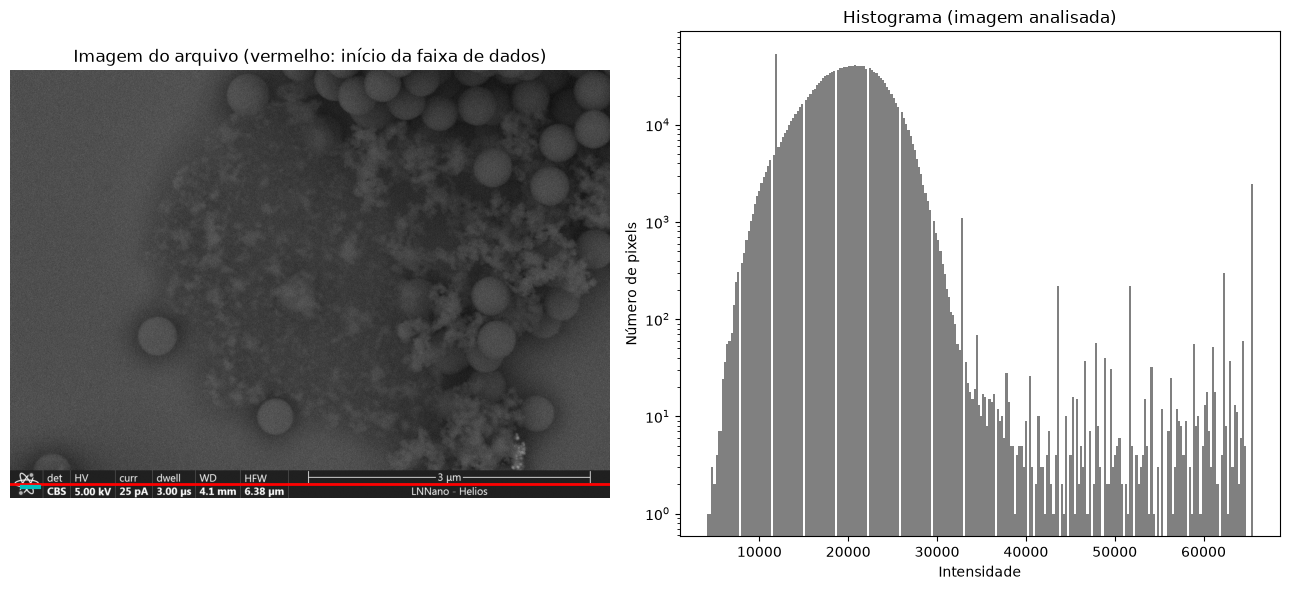

In [16]:
# Faixa de dados do microscópio e calibração do tamanho do pixel

altura_faixa_px = None          # None = detecção automática; 0 = sem faixa de dados; ou o número de linhas a cortar
comprimento_barra_nm = None     # valor escrito na barra de escala, em nm (ex.: 1000 para "1 µm"); só é usado se não houver metadados
tamanho_pixel_nm = None         # se informado (nm/pixel), tem prioridade sobre os metadados e sobre a barra de escala

faixa = None
if altura_faixa_px is None:
    faixa = detectar_faixa_de_dados(imagem_completa)
elif altura_faixa_px > 0:
    faixa = {'linha_inicio': imagem_completa.shape[0] - int(altura_faixa_px),
             'fundo': int(np.bincount(imagem_completa[-1].astype(np.int64)).argmax())}
barra = detectar_barra_de_escala_sem(imagem_completa, faixa) if faixa is not None else None

if faixa is not None:
    print('Faixa de dados: %d linhas (a partir da linha %d)' % (imagem_completa.shape[0] - faixa['linha_inicio'], faixa['linha_inicio']))
else:
    print('Nenhuma faixa de dados detectada: a imagem inteira será analisada.')
if barra is not None:
    print('Barra de escala detectada na faixa: %d pixels' % barra['comprimento_px'])

origem_calibracao = None
if tamanho_pixel_nm is not None:
    origem_calibracao = 'informado manualmente'
else:
    tamanho_pixel_nm, origem_calibracao = ler_calibracao_metadados(filename)
    if tamanho_pixel_nm is None and barra is not None and comprimento_barra_nm is not None:
        tamanho_pixel_nm = comprimento_barra_nm / barra['comprimento_px']
        origem_calibracao = 'barra de escala (%d pixels = %g nm)' % (barra['comprimento_px'], comprimento_barra_nm)

if tamanho_pixel_nm is not None:
    print('Tamanho do pixel: %.4f nm/pixel  [%s]' % (tamanho_pixel_nm, origem_calibracao))
else:
    print('Aviso: tamanho do pixel desconhecido. Informe tamanho_pixel_nm ou comprimento_barra_nm (valor escrito na barra); sem isso, as escalas serão em pixels.')

# A faixa de dados é removida da análise
imagem_raw = imagem_completa[:faixa['linha_inicio']] if faixa is not None else imagem_completa
imagem_original = imagem_raw.astype(np.float32)
scan_height, scan_width = imagem_raw.shape
mascara_valida = np.ones(imagem_raw.shape, dtype=bool)
if tamanho_pixel_nm is not None:
    print('Campo de visão: %.1f x %.1f µm' % (scan_width * tamanho_pixel_nm / 1e3, scan_height * tamanho_pixel_nm / 1e3))

fig, eixos = plt.subplots(1, 2, figsize=(13, 6))
eixos[0].imshow(imagem_completa, cmap='gray')
if faixa is not None:
    eixos[0].axhline(faixa['linha_inicio'], color='r', linewidth=2)
    if barra is not None:
        eixos[0].plot([0.02 * scan_width, 0.02 * scan_width + barra['comprimento_px']], [barra['linha']] * 2, color='c', linewidth=3)
eixos[0].set_title('Imagem do arquivo (vermelho: início da faixa de dados)')
eixos[0].axis('off')
eixos[1].hist(imagem_raw.ravel(), bins=256, color='gray')
eixos[1].set_yscale('log')
eixos[1].set_xlabel('Intensidade'); eixos[1].set_ylabel('Número de pixels'); eixos[1].set_title('Histograma (imagem analisada)')
plt.tight_layout(); plt.show()

Desvio padrão dos deslocamentos de linha removidos: 191.775 níveis de cinza


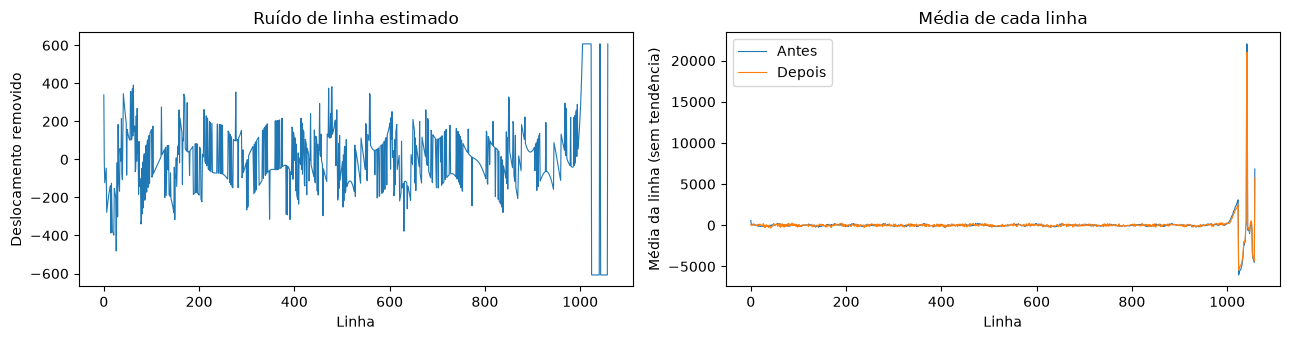

In [17]:
# Correção do ruído de linha da varredura (deslocamentos de brilho entre linhas)

dataset = imagem_original.copy()
corrigir_linhas = True
sigma_linhas = 12.0          # linhas; só deslocamentos mais rápidos que isso são removidos

desloc_linhas = np.zeros(dataset.shape[0])
if corrigir_linhas:
    medias_antes = dataset.mean(axis=1)
    dataset, desloc_linhas = corrigir_listras_de_varredura(dataset, sigma_linhas)
    print('Desvio padrão dos deslocamentos de linha removidos: %.3f níveis de cinza' % desloc_linhas.std())

    fig, eixos = plt.subplots(1, 2, figsize=(13, 3.5))
    eixos[0].plot(desloc_linhas, linewidth=0.8); eixos[0].set_xlabel('Linha'); eixos[0].set_ylabel('Deslocamento removido'); eixos[0].set_title('Ruído de linha estimado')
    eixos[1].plot(medias_antes - ndimage.gaussian_filter1d(medias_antes, 12), linewidth=0.8, label='Antes')
    eixos[1].plot(dataset.mean(axis=1) - ndimage.gaussian_filter1d(dataset.mean(axis=1), 12), linewidth=0.8, label='Depois')
    eixos[1].set_xlabel('Linha'); eixos[1].set_ylabel('Média da linha (sem tendência)'); eixos[1].legend(); eixos[1].set_title('Média de cada linha')
    plt.tight_layout(); plt.show()

Pixels isolados corrigidos: 780


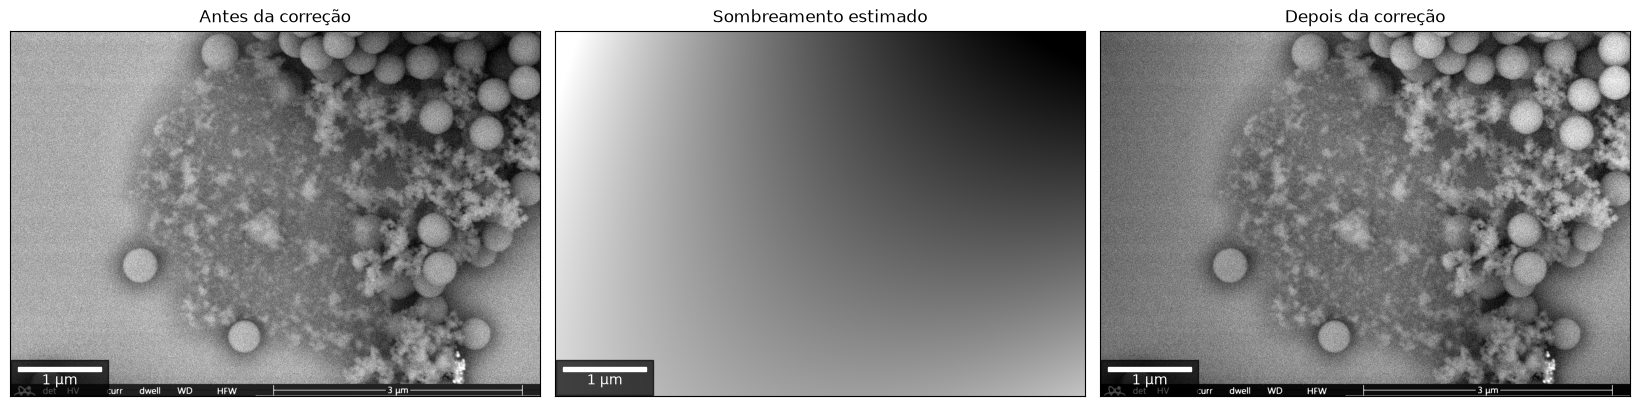

(<Figure size 1650x550 with 3 Axes>,
 array([<Axes: title={'center': 'Antes da correção'}>,
        <Axes: title={'center': 'Sombreamento estimado'}>,
        <Axes: title={'center': 'Depois da correção'}>], dtype=object))

In [18]:
# Remoção de pixels quentes e correção de sombreamento (flatfield)

# Pixels quentes
dataset, n_quentes = remover_pixels_quentes(dataset, limiar_sigma=6.0, mascara=mascara_valida)
print('Pixels isolados corrigidos:', n_quentes)

# Sombreamento do detector
if usar_flatfield_externo:
    flatfield = tifffile.imread(flat_field).astype('float32')
    if flatfield.shape != dataset.shape:
        raise ValueError('O flatfield deve ter a mesma dimensão da imagem analisada: ' + str(flatfield.shape) + ' != ' + str(dataset.shape))
    fundo = flatfield
else:
    # rejeição simétrica: partículas claras e poros escuros não entram no ajuste do sombreamento
    fundo = estimar_fundo_polinomial(dataset, mascara_valida, ordem=ordem_polinomio, k_baixo=2.5, k_alto=2.5)

dataset_sem_flat = dataset.copy()
if modo_flatfield == 'aditivo':
    dataset = dataset - fundo + fundo.mean()
else:
    dataset = dataset / fundo * fundo.mean()
dataset_flat = dataset.copy()

mostrar_imagens([dataset_sem_flat, fundo, dataset_flat],
                ['Antes da correção', 'Sombreamento estimado', 'Depois da correção'],
                pixel_nm=tamanho_pixel_nm, tamanho=5.5)

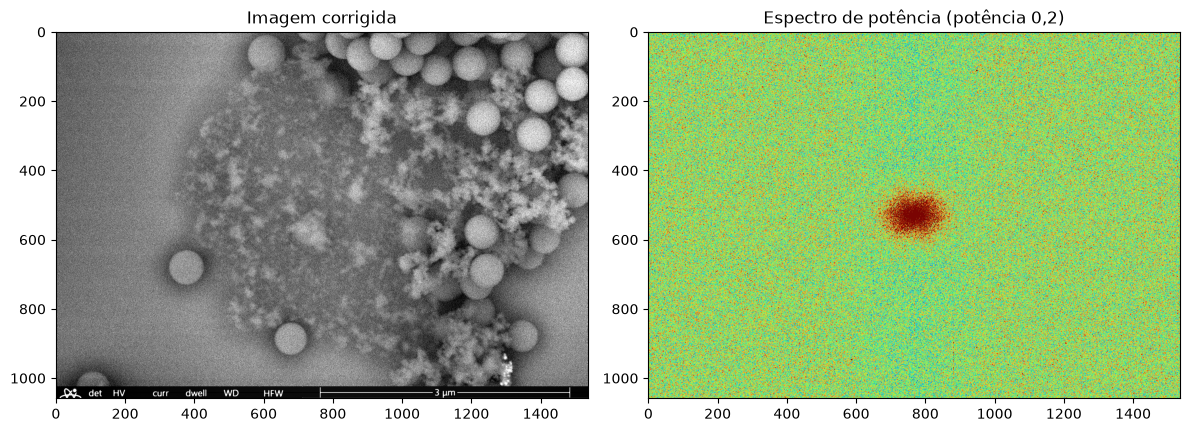

(<Figure size 1200x600 with 2 Axes>,
 array([<Axes: title={'center': 'Imagem corrigida'}>,
        <Axes: title={'center': 'Espectro de potência (potência 0,2)'}>],
       dtype=object))

In [19]:
# Calcula o espectro de potência médio (análogo ao padrão de difração médio)
dp_mean = espectro_de_potencia(dataset)

# plota a imagem corrigida e o espectro de potência
mostrar_imagens(
    [dataset, dp_mean ** 0.2],
    ['Imagem corrigida', 'Espectro de potência (potência 0,2)'],
    cmaps=['gray', 'turbo'],
    tamanho=6,
)

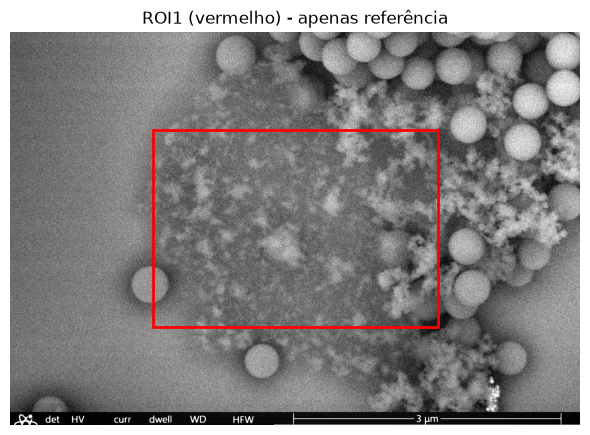

Dimensões do conjunto analisado: (1059, 1536)
Tamanho do pixel: 4.1506 nm


In [20]:
# Redução do conjunto de dados (binning, recorte)

# ROI1 = (linha_min, linha_max, coluna_min, coluna_max), em pixels da imagem analisada
ROI1 = (scan_height // 4, 3 * scan_height // 4, scan_width // 4, 3 * scan_width // 4)

# Neste notebook a imagem inteira é analisada por padrão (para medir todos os objetos).
# Para analisar apenas a ROI1, use aplicar_recorte = True.
aplicar_recorte = False

# Fator de binning
R_bin_factor = 1

dataset_backup = dataset.copy()
recorte = (slice(ROI1[0], ROI1[1]), slice(ROI1[2], ROI1[3])) if aplicar_recorte else (slice(None), slice(None))
dataset = agrupar_pixels(dataset_backup[recorte], R_bin_factor)
imagem_original_roi = agrupar_pixels(imagem_original[recorte], R_bin_factor)
mascara_roi = np.ones(dataset.shape, dtype=bool)
tamanho_pixel_roi = tamanho_pixel_nm * R_bin_factor if tamanho_pixel_nm is not None else None

fig, eixo = plt.subplots(figsize=(6, 6))
eixo.imshow(dataset_backup, cmap='gray', vmin=np.percentile(dataset_backup, 0.5), vmax=np.percentile(dataset_backup, 99.5))
eixo.add_patch(patches.Rectangle((ROI1[2], ROI1[0]), ROI1[3] - ROI1[2], ROI1[1] - ROI1[0], fill=False, edgecolor='r', linewidth=2))
eixo.set_title('ROI1 (vermelho)' + (' - aplicada' if aplicar_recorte else ' - apenas referência')); eixo.axis('off')
plt.tight_layout(); plt.show()

print('Dimensões do conjunto analisado:', dataset.shape)
if tamanho_pixel_roi is not None:
    print('Tamanho do pixel: %.4f nm' % tamanho_pixel_roi)

In [21]:
# Salva o conjunto reduzido (desative o comentário se quiser gravar)
# tifffile.imwrite(
#     os.path.splitext(filename)[0] + '_SAIDA_binr' + str(R_bin_factor) + '.tif',
#     dataset.astype(np.float32),
# )

# Pré-processamento em etapas (perfis SCIENTIFIC e VISUAL)
Equilíbrio tonal, gama, redução de ruído Non-Local Means, CLAHE, suavização controlada, nitidez e ajuste tonal final.
- **SCIENTIFIC**: preserva a informação estrutural (usado nas medidas). - **VISUAL**: suavidade e destaque dos contornos (usado nas figuras).

In [22]:
# Parâmetros - Versão A: SCIENTIFIC
parametros_scientific = {
    'black_point': 0.3,
    'white_point': 99.7,
    'gamma': 0.98,

    'denoise_strength': 'auto',   # 'auto' = proporcional ao ruído medido (ou um valor fixo de h)
    'denoise_fator': 0.6,

    'clahe_limit': 1.0,
    'clahe_grid': (8, 8),

    'smooth_strength': 0.05,
    'smooth_sigma': 0.6,

    'sharp_strength': 0.25,
    'sharp_sigma': 1.0,

    'final_percentiles': (0.1, 99.9),
}

# Parâmetros - Versão B: VISUAL
parametros_visual = {
    'black_point': 0.5,
    'white_point': 99.7,
    'gamma': 0.95,

    'denoise_strength': 'auto',
    'denoise_fator': 1.0,

    'clahe_limit': 1.5,
    'clahe_grid': (8, 8),

    'smooth_strength': 0.15,
    'smooth_sigma': 0.8,

    'sharp_strength': 0.40,
    'sharp_sigma': 1.0,

    'final_percentiles': (0.2, 99.8),
}

Força do filtro Non-Local Means (h): scientific = 15.10 | visual = 25.38
Versão SCIENTIFIC | média = 0.4430 | desvio padrão = 0.1801 | mín = 0.000 | máx = 1.000
Versão VISUAL | média = 0.4558 | desvio padrão = 0.1744 | mín = 0.000 | máx = 1.000


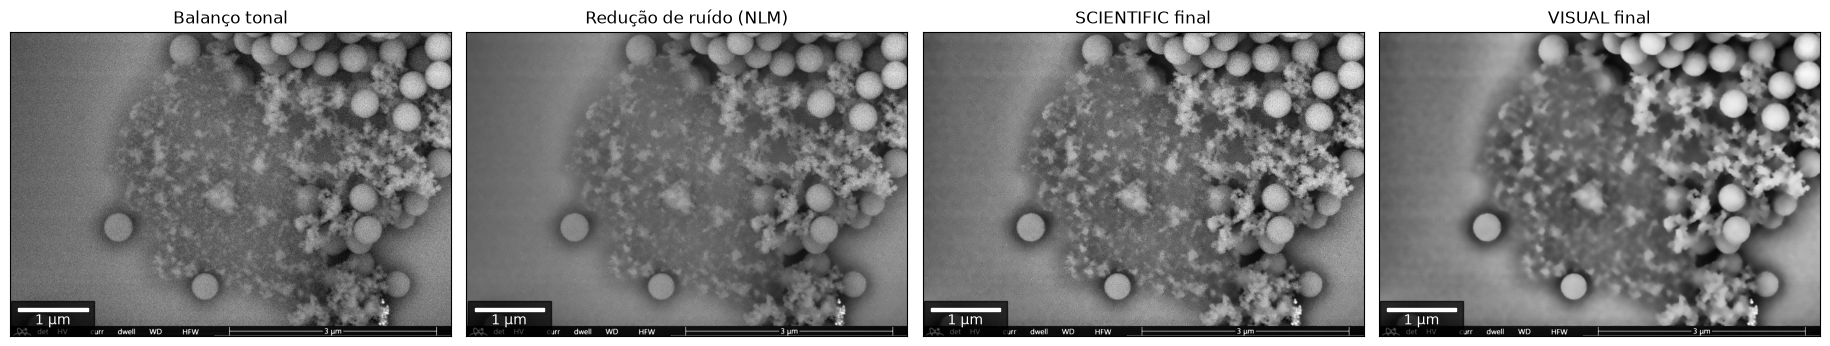

(<Figure size 1840x460 with 4 Axes>,
 array([<Axes: title={'center': 'Balanço tonal'}>,
        <Axes: title={'center': 'Redução de ruído (NLM)'}>,
        <Axes: title={'center': 'SCIENTIFIC final'}>,
        <Axes: title={'center': 'VISUAL final'}>], dtype=object))

In [23]:
# Execução das duas versões sobre a região analisada

resultados_scientific = processar_imagem(dataset, parametros_scientific, mascara_roi)
resultados_visual = processar_imagem(dataset, parametros_visual, mascara_roi)

dataset_norm = resultados_scientific['balance']
dataset_balance = resultados_scientific['balance']
dataset_gamma = resultados_scientific['gamma']
dataset_denoised = resultados_scientific['denoised']
dataset_eq = resultados_scientific['clahe']
dataset_clahe = resultados_scientific['clahe']
dataset_smooth = resultados_scientific['smooth']
dataset_sharp = resultados_scientific['sharp']

dataset_scientific = resultados_scientific['final']
dataset_visual = resultados_visual['final']

print('Força do filtro Non-Local Means (h): scientific = %.2f | visual = %.2f' % (resultados_scientific['h_nlm'], resultados_visual['h_nlm']))
for nome, img in (('SCIENTIFIC', dataset_scientific), ('VISUAL', dataset_visual)):
    print('Versão', nome, '| média = %.4f | desvio padrão = %.4f | mín = %.3f | máx = %.3f' % (img.mean(), img.std(), img.min(), img.max()))

mostrar_imagens([dataset_norm, dataset_denoised, dataset_scientific, dataset_visual],
                ['Balanço tonal', 'Redução de ruído (NLM)', 'SCIENTIFIC final', 'VISUAL final'],
                pixel_nm=tamanho_pixel_roi, vlims=[(0, 1)] * 4, tamanho=4.6)

In [24]:
# Imagem linear sem ruído e imagem de sinal (as medidas usam intensidades, sem gama nem CLAHE)

# 'claro': partículas ou grãos mais claros que o fundo | 'escuro': poros ou cavidades mais escuros que o fundo
tipo_objeto = 'claro'

escala_lin = 1.0 / np.percentile(dataset, 99.9)
linear = reduzir_ruido(np.clip(dataset * escala_lin, 0, 1), resultados_scientific['h_nlm']) / escala_lin

# O sinal é positivo onde há objeto; o nível de referência é o nível de cinza dominante da imagem
contagem, bordas = np.histogram(linear[mascara_roi], bins=256)
contagem = ndimage.uniform_filter1d(contagem.astype(float), 5)
I0 = float(0.5 * (bordas[:-1] + bordas[1:])[int(np.argmax(contagem))])
sinal = ((linear - I0) if tipo_objeto == 'claro' else (I0 - linear)).astype(np.float32)
print('Nível dominante (I0): %.2f | objetos %ss' % (I0, tipo_objeto))

Nível dominante (I0): 19639.27 | objetos claros


# Calibração

Raio típico = 27.8 pixels (115.6 nm)


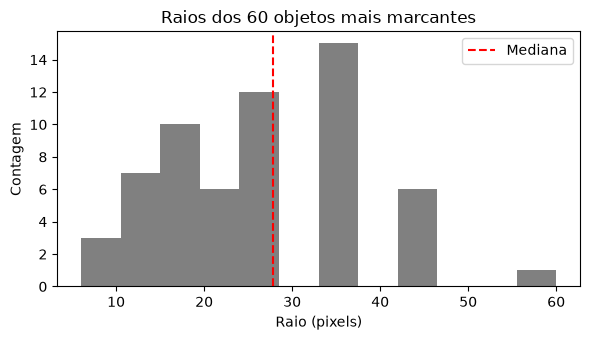

In [25]:
# Estima o raio típico dos objetos por espaço-escala (análogo ao raio da sonda)
# Limites de busca (em pixels): ajuste conforme o tamanho dos objetos de interesse
raio_min_busca, raio_max_busca = 6.0, 60.0

probe_radius_pixels, raios_top, centros_LoG = estimar_raio_caracteristico(
    -sinal, mascara_roi, raio_min=raio_min_busca, raio_max=raio_max_busca, n_top=60,
)
if tamanho_pixel_roi is not None:
    print('Raio típico = %.1f pixels (%.1f nm)' % (probe_radius_pixels, probe_radius_pixels * tamanho_pixel_roi))
else:
    print('Raio típico = %.1f pixels' % probe_radius_pixels)

plt.figure(figsize=(6, 3.5))
plt.hist(raios_top, bins=12, color='gray')
plt.axvline(probe_radius_pixels, color='r', linestyle='--', label='Mediana')
plt.xlabel('Raio (pixels)'); plt.ylabel('Contagem'); plt.title('Raios dos 60 objetos mais marcantes'); plt.legend()
plt.tight_layout(); plt.show()

In [26]:
# calibração do tamanho de pixel no espaço real - metadados, barra de escala ou valor manual
# calibração no espaço de Fourier - a partir do tamanho do campo de visão
calibracao = {
    'R_pixel_size': tamanho_pixel_roi if tamanho_pixel_roi is not None else 1.0,
    'R_pixel_units': 'nm' if tamanho_pixel_roi is not None else 'px',
}
calibracao['Q_pixel_size'] = 1.0 / (dataset.shape[1] * calibracao['R_pixel_size'])
calibracao['Q_pixel_units'] = 'nm^-1' if tamanho_pixel_roi is not None else 'px^-1'
print(calibracao)

fator_nm = calibracao['R_pixel_size']
unidade = calibracao['R_pixel_units']
area_imagem = dataset.size * fator_nm ** 2
unidade_area = unidade + '²' if unidade == 'px' else 'nm²'
if tamanho_pixel_roi is not None:
    area_imagem_um2 = area_imagem / 1e6
    print('Área analisada: %.2f µm²' % area_imagem_um2)

{'R_pixel_size': 4.150639999999999, 'R_pixel_units': 'nm', 'Q_pixel_size': 0.00015685332061240358, 'Q_pixel_units': 'nm^-1'}
Área analisada: 28.02 µm²


# Imagens virtuais
### Faixas de BF (disco) e ADF (anel) no espaço real

In [27]:
# Cálculo das imagens virtuais de campo claro e de campo escuro

# expande o raio em 5 pixels para separar o disco central do anel
expand_BF = 5.0

radius_BF = probe_radius_pixels
radii_DF = (probe_radius_pixels + expand_BF, 3 * probe_radius_pixels + expand_BF)

bright_field = imagem_virtual_real(linear, 'circle', radius_BF)
dark_field = imagem_virtual_real(linear, 'annulus', radii_DF)

# Contraste centro-periferia: positivo onde o disco é mais claro que o anel ao redor (objetos claros)
contraste_centro_periferia = (bright_field - dark_field) if tipo_objeto == 'claro' else (dark_field - bright_field)

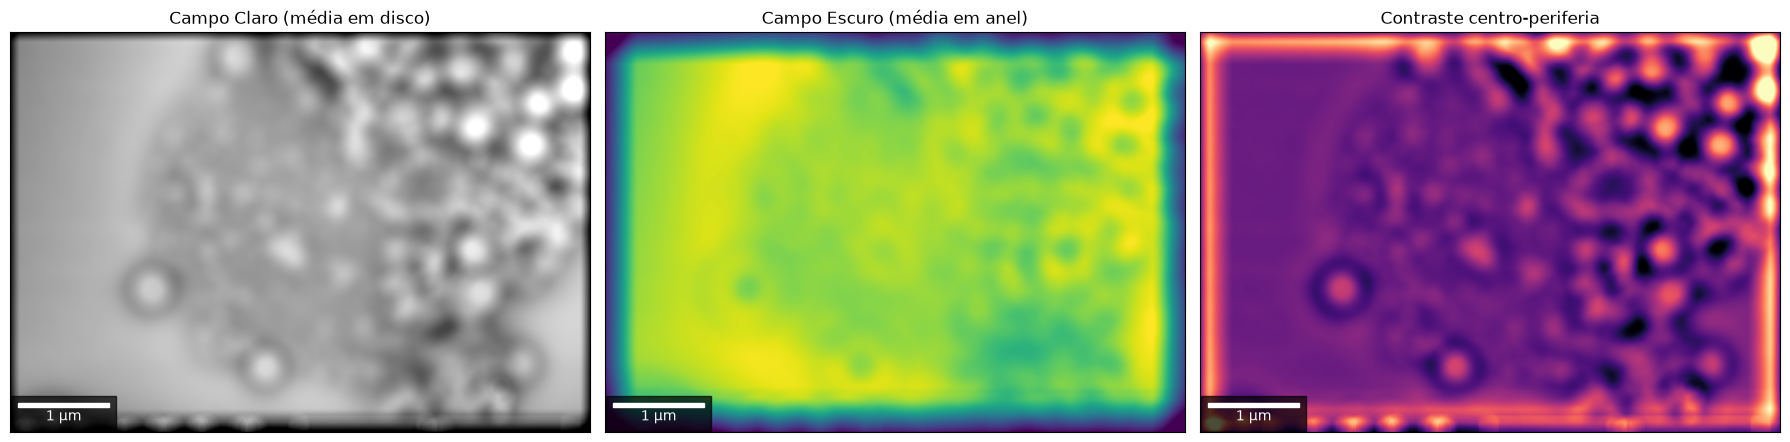

(<Figure size 1800x600 with 3 Axes>,
 array([<Axes: title={'center': 'Campo Claro (média em disco)'}>,
        <Axes: title={'center': 'Campo Escuro (média em anel)'}>,
        <Axes: title={'center': 'Contraste centro-periferia'}>],
       dtype=object))

In [28]:
# plota as imagens virtuais
mostrar_imagens(
    [bright_field, dark_field, contraste_centro_periferia],
    ['Campo Claro (média em disco)', 'Campo Escuro (média em anel)', 'Contraste centro-periferia'],
    cmaps=['gray', 'viridis', 'magma'],
    pixel_nm=tamanho_pixel_roi,
    tamanho=6,
)

# Imagem de realce e detecção dos objetos

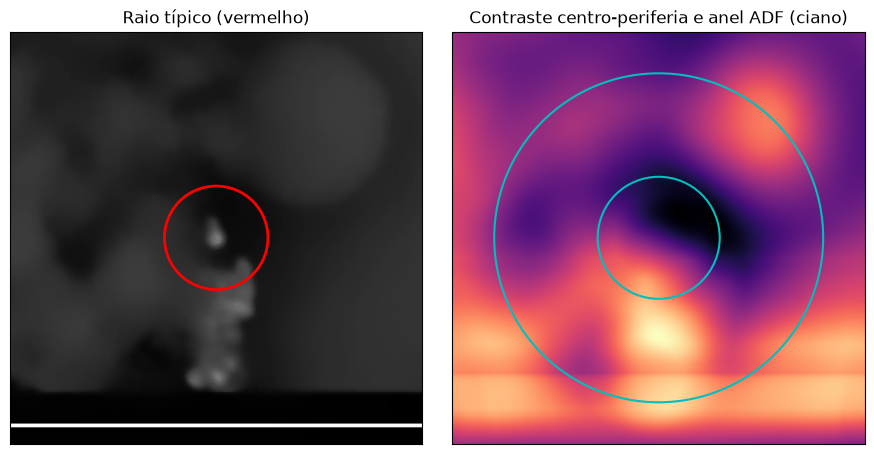

Raio estimado do objeto = 27.85 pixels


In [29]:
# Estima o raio e o centro do objeto mais marcante
probe_semiangle = probe_radius_pixels
probe_qx0, probe_qy0 = centros_LoG[0]
center = (probe_qx0, probe_qy0)

# plota a região em torno dele, com o raio estimado sobreposto como um círculo
L = int(4 * probe_semiangle)
x0, y0 = int(probe_qx0), int(probe_qy0)
recorte_p = (slice(max(y0 - L, 0), y0 + L), slice(max(x0 - L, 0), x0 + L))
ext = (recorte_p[1].start, recorte_p[1].stop, recorte_p[0].stop, recorte_p[0].start)
fig, eixos = plt.subplots(1, 2, figsize=(9, 4.5))
eixos[0].imshow(linear[recorte_p], cmap='gray', extent=ext)
eixos[0].add_patch(patches.Circle(center, probe_semiangle, fill=False, edgecolor='r', linewidth=2))
eixos[0].set_title('Raio típico (vermelho)')
# Detector ADF (anel) sobre a mesma região e contraste centro-periferia
eixos[1].imshow(contraste_centro_periferia[recorte_p], cmap='magma', extent=ext)
for raio_i in radii_DF:
    eixos[1].add_patch(patches.Circle(center, raio_i, fill=False, edgecolor='c', linewidth=1.5))
eixos[1].set_title('Contraste centro-periferia e anel ADF (ciano)')
for e in eixos: e.set_xticks([]); e.set_yticks([])
plt.tight_layout(); plt.show()

# Imprime o raio estimado
print('Raio estimado do objeto =', '%.2f' % probe_semiangle, 'pixels')

In [30]:
# Sonda de vácuo (template): média alinhada de até 25 objetos isolados
try:
    probe_template, n_usadas = construir_template(sinal, centros_LoG, probe_semiangle, mascara_roi, n_max=25, fator_isolamento=3.0)
except RuntimeError:
    print('Poucos objetos isolados: relaxando o critério de isolamento.')
    probe_template, n_usadas = construir_template(sinal, centros_LoG, probe_semiangle, mascara_roi, n_max=25, fator_isolamento=1.5)
probe = SimpleNamespace(template=probe_template)
print('Template construído com', n_usadas, 'objetos')

Template construído com 13 objetos


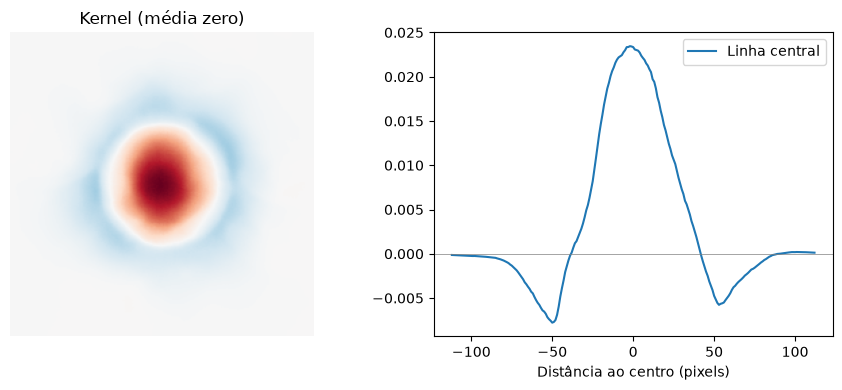

In [31]:
# Subtrai uma função de normalização para que o template tenha valor médio zero
probe.kernel = criar_kernel(
    probe.template,
    probe_semiangle,
    radii = (0.0, 4.0),        # em unidades do raio estimado
    bilinear = True,
)

# Plota o kernel
fig, eixos = plt.subplots(1, 2, figsize=(9, 4))
eixos[0].imshow(probe.kernel, cmap='RdBu_r', vmin=-np.abs(probe.kernel).max(), vmax=np.abs(probe.kernel).max())
eixos[0].set_title('Kernel (média zero)'); eixos[0].axis('off')
centro_k = probe.kernel.shape[0] // 2
eixos[1].plot(np.arange(-centro_k, centro_k + 1), probe.kernel[centro_k], label='Linha central')
eixos[1].axhline(0, color='gray', linewidth=0.5); eixos[1].set_xlabel('Distância ao centro (pixels)'); eixos[1].legend()
plt.tight_layout(); plt.show()

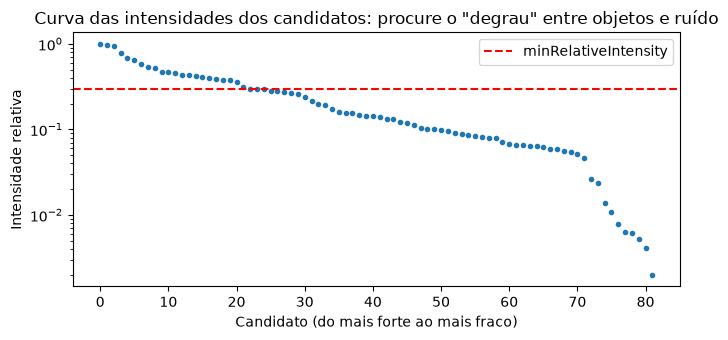

Objetos detectados: 22


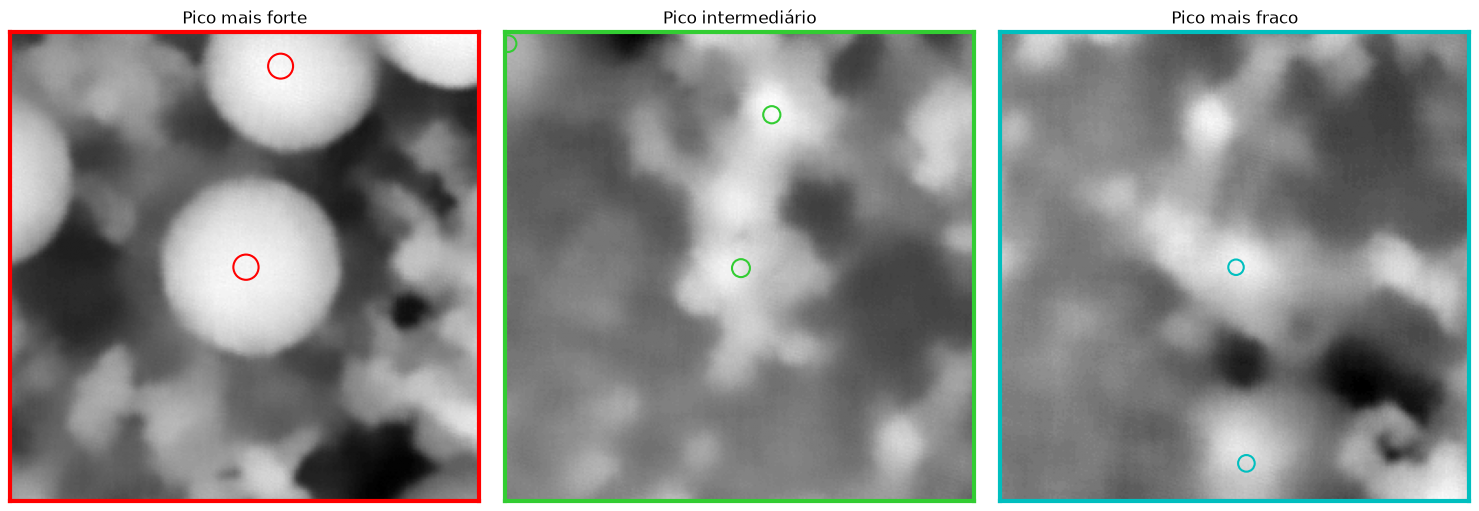

In [32]:
# Testa os parâmetros em alguns objetos
# Visualiza a imagem e as posições localizadas

# parâmetros
detect_params = {
    'corrPower': 1,
    'sigma': 2,
    'edgeBoundary': 10,
    'minRelativeIntensity': 0.3,     # fração da correlação máxima; veja a curva abaixo para ajustar
    'minAbsoluteIntensity': 0,
    'minPeakSpacing': int(round(1.5 * probe_semiangle)),
    # 'subpixel' : 'poly',
    'subpixel' : 'multicorr',
    'upsample_factor': 8,
    'maxNumPeaks': 2000,
    # 'CUDA': True,    (não se aplica: a correlação é feita por FFT na CPU)
}

# Todos os candidatos (sem limiar relativo) para visualizar onde o limiar separa objetos reais do ruído
candidatos, corr_mapa = detectar_picos(
    sinal,
    probe.kernel,
    mascara_valida = mascara_roi,
    **{**detect_params, 'minRelativeIntensity': 0.0},
)
intensidade_rel = candidatos['intensidade'] / candidatos['intensidade'].max()

plt.figure(figsize=(7, 3.5))
plt.semilogy(np.sort(intensidade_rel)[::-1], 'o', markersize=3)
plt.axhline(detect_params['minRelativeIntensity'], color='r', linestyle='--', label='minRelativeIntensity')
plt.xlabel('Candidato (do mais forte ao mais fraco)'); plt.ylabel('Intensidade relativa'); plt.legend()
plt.title('Curva das intensidades dos candidatos: procure o "degrau" entre objetos e ruído')
plt.tight_layout(); plt.show()

selecionados = intensidade_rel >= detect_params['minRelativeIntensity']
picos_teste = {k: v[selecionados] for k, v in candidatos.items()}
print('Objetos detectados:', len(picos_teste['x']))

# Janelas de teste centradas no pico mais forte, em um intermediário e no mais fraco
ordem_int = np.argsort(picos_teste['intensidade'])[::-1]
escolhidos = [ordem_int[0], ordem_int[len(ordem_int) // 2], ordem_int[-1]]
janela_teste = int(min(256, dataset.shape[0], dataset.shape[1]))
colors = ['r', 'limegreen', 'c']

fig, eixos = plt.subplots(1, 3, figsize=(15, 5))
for eixo, k, cor in zip(eixos, escolhidos, colors):
    cx, cy = picos_teste['x'][k], picos_teste['y'][k]
    x_ini = int(np.clip(cx - janela_teste // 2, 0, dataset.shape[1] - janela_teste))
    y_ini = int(np.clip(cy - janela_teste // 2, 0, dataset.shape[0] - janela_teste))
    eixo.imshow(linear[y_ini:y_ini + janela_teste, x_ini:x_ini + janela_teste], cmap='gray',
                extent=(x_ini, x_ini + janela_teste, y_ini + janela_teste, y_ini))
    dentro = ((picos_teste['x'] >= x_ini) & (picos_teste['x'] < x_ini + janela_teste) &
              (picos_teste['y'] >= y_ini) & (picos_teste['y'] < y_ini + janela_teste))
    eixo.scatter(picos_teste['x'][dentro], picos_teste['y'][dentro], s=300 * picos_teste['intensidade'][dentro] / picos_teste['intensidade'].max() + 30,
                 facecolors='none', edgecolors=cor, linewidths=1.5)
    for lado in eixo.spines.values():
        lado.set_edgecolor(cor); lado.set_linewidth(3)
    eixo.set_xticks([]); eixo.set_yticks([])
eixos[0].set_title('Pico mais forte'); eixos[1].set_title('Pico intermediário'); eixos[2].set_title('Pico mais fraco')
plt.tight_layout(); plt.show()

# Localização dos objetos em toda a imagem

Objetos detectados: 22


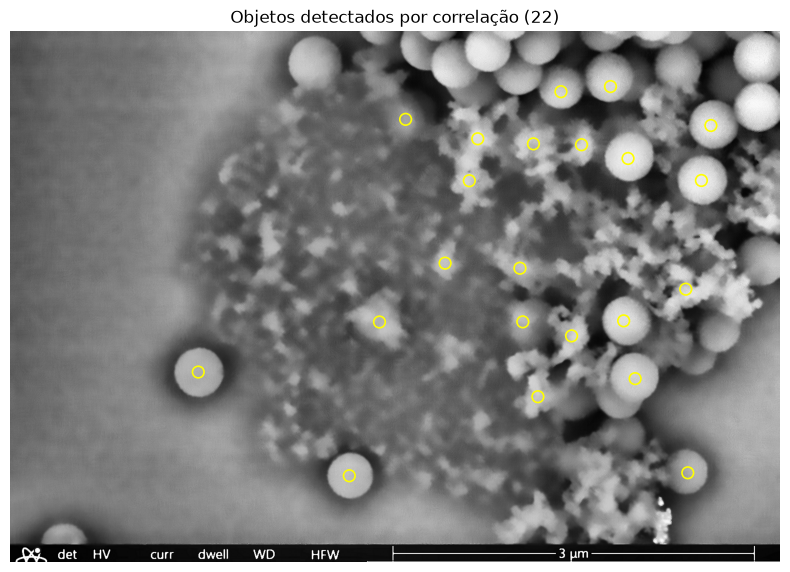

In [33]:
picos, corr_mapa = detectar_picos(
    sinal,
    probe.kernel,
    mascara_valida = mascara_roi,
    **detect_params,
)
bragg_peaks = picos      # nome mantido do fluxo original: lista de posições detectadas
print('Objetos detectados:', len(picos['x']))

fig, eixo = plt.subplots(figsize=(8, 8))
eixo.imshow(dataset_visual, cmap='gray', vmin=0, vmax=1)
eixo.scatter(picos['x'], picos['y'], s=70, facecolors='none', edgecolors='yellow', linewidths=1.2)
eixo.set_title('Objetos detectados por correlação (' + str(len(picos['x'])) + ')'); eixo.axis('off')
plt.tight_layout(); plt.show()

# Centralização e calibração

Objetos medidos: 22
Deslocamento médio do refinamento: 3.39 pixels (máx. 9.39)


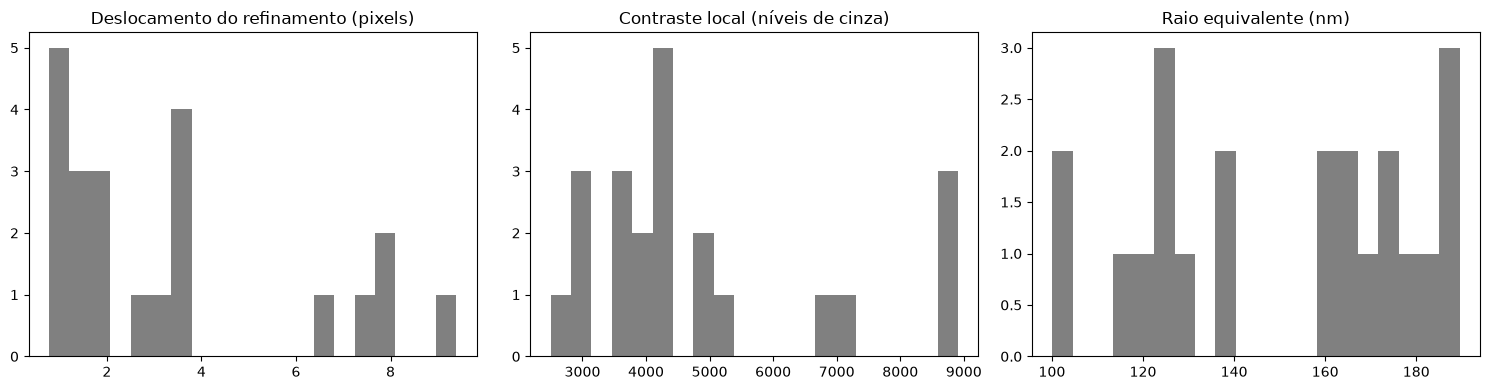

In [34]:
# Refina o centro de cada objeto (centro de massa) e mede contraste, raio equivalente e fundo local

# mede as origens
particulas = refinar_centros_com(sinal, picos, probe_semiangle)
qxy_origins = np.column_stack([particulas['x'], particulas['y']])

print('Objetos medidos:', len(particulas['x']))
print('Deslocamento médio do refinamento: %.2f pixels (máx. %.2f)' % (particulas['deslocamento'].mean(), particulas['deslocamento'].max()))

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
eixos[0].hist(particulas['deslocamento'], bins=20, color='gray'); eixos[0].set_title('Deslocamento do refinamento (pixels)')
eixos[1].hist(particulas['contraste'], bins=20, color='gray'); eixos[1].set_title('Contraste local (níveis de cinza)')
eixos[2].hist(particulas['raio_eq'] * fator_nm, bins=20, color='gray')
eixos[2].set_title('Raio equivalente (' + unidade + ')')
plt.tight_layout(); plt.show()

Inclinação do nível local: -1.03e+00 níveis/pixel em x, 9.61e-01 em y | desvio dos resíduos: 674.40


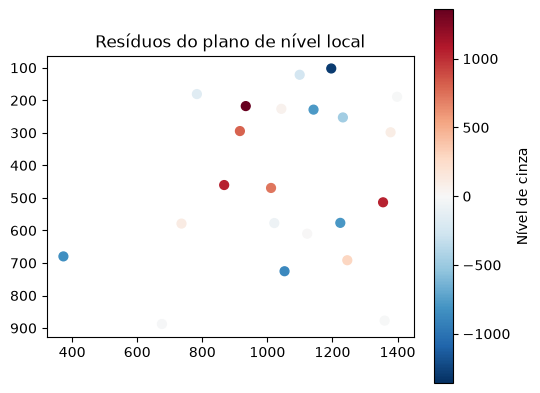

In [35]:
# ajusta um plano ao nível de fundo local ao redor dos objetos (diagnóstico do sombreamento residual)
coef_plano, residuos_plano = ajustar_plano(particulas['x'], particulas['y'], particulas['fundo'])
qx0_fit, qy0_fit = coef_plano[0], coef_plano[1]
print('Inclinação do nível local: %.2e níveis/pixel em x, %.2e em y | desvio dos resíduos: %.2f' % (coef_plano[0], coef_plano[1], residuos_plano.std()))

fig, eixo = plt.subplots(figsize=(5.5, 5))
sc = eixo.scatter(particulas['x'], particulas['y'], c=residuos_plano, cmap='RdBu_r', s=40,
                  vmin=-np.abs(residuos_plano).max(), vmax=np.abs(residuos_plano).max())
eixo.invert_yaxis(); eixo.set_aspect('equal'); eixo.set_title('Resíduos do plano de nível local')
plt.colorbar(sc, ax=eixo, fraction=0.046, label='Nível de cinza')
plt.tight_layout(); plt.show()

# Segmentação e distribuição de tamanhos

Objetos segmentados: 70 (61 inteiros, 9 tocam a borda)
Fração de área ocupada pelos objetos (cobertura): 25.7%
Diâmetro equivalente (nm): média = 299.6 | desvio = 148.9 | D10 = 185.9 | D50 = 247.9 | D90 = 400.7 | amplitude relativa = 0.87
Circularidade média: 0.720 | razão de aspecto média: 1.45


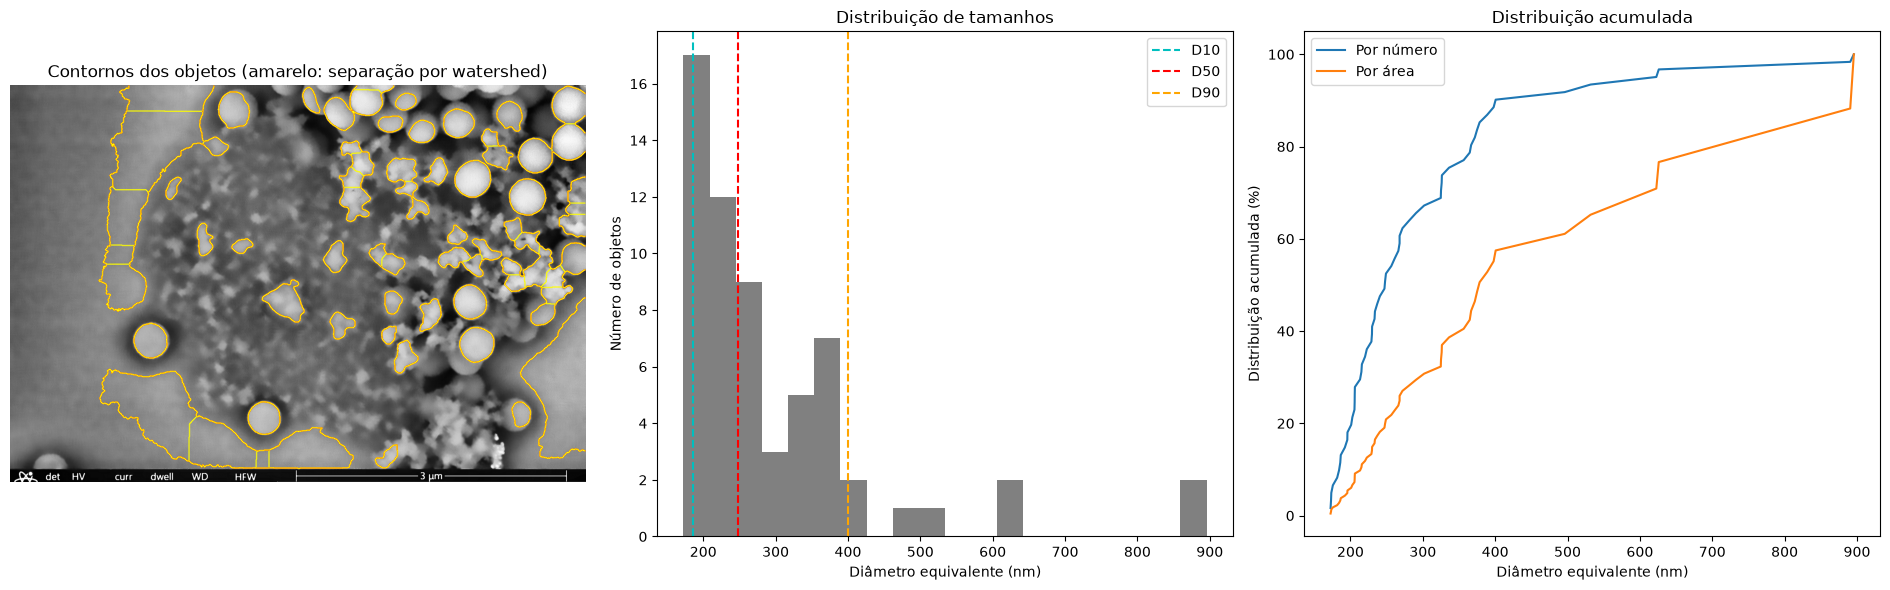

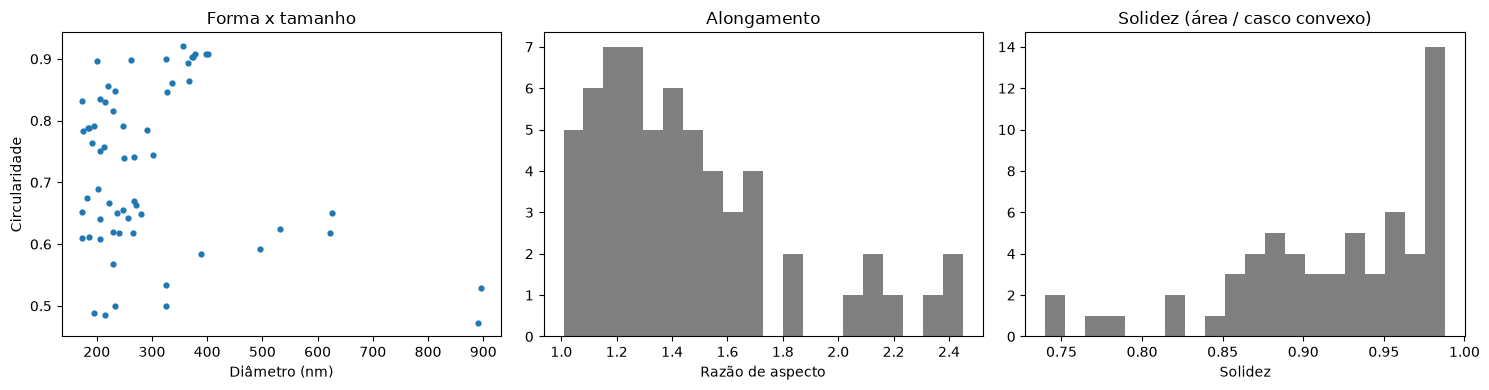

In [36]:
# Análise 1 - segmentação dos objetos, medidas de forma e distribuição de tamanhos

# Parâmetros de segmentação
metodo_limiar = 'multiotsu'                                         # 'multiotsu' (3 níveis: poros/matriz/partículas), 'otsu' (2 fases) ou 'local' (sombreamento forte)
sigma_seg = 1.5                                                     # pixels
area_min_px = int(np.pi * (0.7 * probe_semiangle) ** 2)             # área mínima de um objeto (aumente para descartar fragmentos de textura)
distancia_min = max(int(0.5 * probe_semiangle), 3)                  # distância mínima entre sementes do watershed (pixels)

rotulos, binaria, limiar_seg = segmentar_objetos(
    linear, mascara_roi, claro=(tipo_objeto == 'claro'), sigma=sigma_seg, metodo=metodo_limiar,
    area_min=area_min_px, distancia_min=distancia_min,
)
objetos = medir_objetos(rotulos, linear)
n_obj = len(objetos['id'])
internos = ~objetos['toca_borda']          # as estatísticas de tamanho ignoram objetos cortados pela borda da imagem
print('Objetos segmentados: %d (%d inteiros, %d tocam a borda)' % (n_obj, internos.sum(), n_obj - internos.sum()))

cobertura = float(binaria.mean())
print('Fração de área ocupada pelos objetos (%s): %.1f%%' % ('cobertura' if tipo_objeto == 'claro' else 'porosidade', 100 * cobertura))

diam = objetos['diam_eq'][internos] * fator_nm
est = estatisticas_distribuicao(diam)
print('Diâmetro equivalente (%s): média = %.1f | desvio = %.1f | D10 = %.1f | D50 = %.1f | D90 = %.1f | amplitude relativa = %.2f' % (unidade, est['media'], est['desvio'], est['D10'], est['D50'], est['D90'], est['amplitude_rel']))
print('Circularidade média: %.3f | razão de aspecto média: %.2f' % (objetos['circularidade'][internos].mean(), objetos['razao_aspecto'][internos].mean()))

fig, eixos = plt.subplots(1, 3, figsize=(19, 6))
eixos[0].imshow(dataset_visual, cmap='gray', vmin=0, vmax=1)
eixos[0].contour(rotulos > 0, levels=[0.5], colors='r', linewidths=0.8)
eixos[0].contour(segmentation.find_boundaries(rotulos), levels=[0.5], colors='yellow', linewidths=0.4)
eixos[0].set_title('Contornos dos objetos (amarelo: separação por watershed)'); eixos[0].axis('off')
eixos[1].hist(diam, bins=20, color='gray')
for nome_p, valor_p, cor in (('D10', est['D10'], 'c'), ('D50', est['D50'], 'r'), ('D90', est['D90'], 'orange')):
    eixos[1].axvline(valor_p, color=cor, linestyle='--', label=nome_p)
eixos[1].set_xlabel('Diâmetro equivalente (' + unidade + ')'); eixos[1].set_ylabel('Número de objetos'); eixos[1].legend(); eixos[1].set_title('Distribuição de tamanhos')
d_ord = np.sort(diam)
area_ord = np.pi / 4 * d_ord ** 2
eixos[2].plot(d_ord, 100 * np.arange(1, len(d_ord) + 1) / len(d_ord), label='Por número')
eixos[2].plot(d_ord, 100 * np.cumsum(area_ord) / area_ord.sum(), label='Por área')
eixos[2].set_xlabel('Diâmetro equivalente (' + unidade + ')'); eixos[2].set_ylabel('Distribuição acumulada (%)'); eixos[2].legend(); eixos[2].set_title('Distribuição acumulada')
plt.tight_layout(); plt.show()

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
eixos[0].scatter(diam, objetos['circularidade'][internos], s=12); eixos[0].set_xlabel('Diâmetro (' + unidade + ')'); eixos[0].set_ylabel('Circularidade'); eixos[0].set_title('Forma x tamanho')
eixos[1].hist(objetos['razao_aspecto'][internos], bins=20, color='gray'); eixos[1].set_xlabel('Razão de aspecto'); eixos[1].set_title('Alongamento')
eixos[2].hist(objetos['solidez'][internos], bins=20, color='gray'); eixos[2].set_xlabel('Solidez'); eixos[2].set_title('Solidez (área / casco convexo)')
plt.tight_layout(); plt.show()

# Mapa de vetores, distribuição radial e estatística espacial

Posições usadas: 61 (fonte: segmentacao)


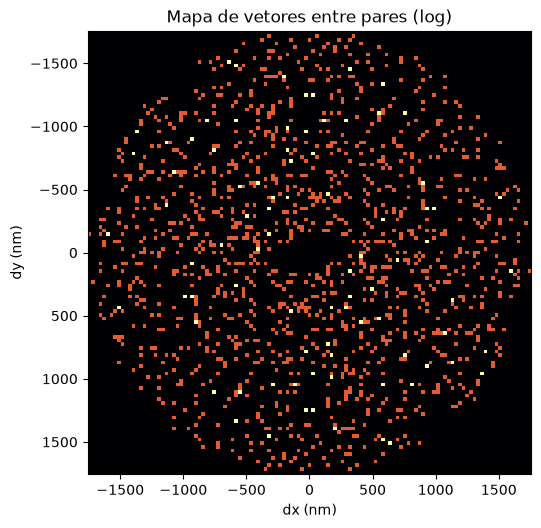

In [37]:
# Posições usadas nas análises espaciais: 'segmentacao' (centroides dos objetos inteiros) ou 'correlacao' (detecção refinada)
fonte_posicoes = 'segmentacao'

if fonte_posicoes == 'segmentacao':
    pos_x, pos_y = objetos['x'][internos], objetos['y'][internos]
else:
    pos_x, pos_y = particulas['x'], particulas['y']
print('Posições usadas:', len(pos_x), '(fonte: ' + fonte_posicoes + ')')

# Calcula o mapa de vetores entre pares de objetos (análogo ao BVM calculado dos dados centralizados)
r_max_pares = min(20 * probe_semiangle, 0.4 * min(dataset.shape))
mapa_pares = mapa_de_pares(pos_x, pos_y, r_max_pares, passo=max(probe_semiangle / 4, 1.0))

fig, eixo = plt.subplots(figsize=(5.5, 5.5))
eixo.imshow(np.log1p(mapa_pares), cmap='inferno', extent=(-r_max_pares * fator_nm, r_max_pares * fator_nm, r_max_pares * fator_nm, -r_max_pares * fator_nm))
eixo.set_title('Mapa de vetores entre pares (log)'); eixo.set_xlabel('dx (' + unidade + ')'); eixo.set_ylabel('dy (' + unidade + ')')
plt.tight_layout(); plt.show()

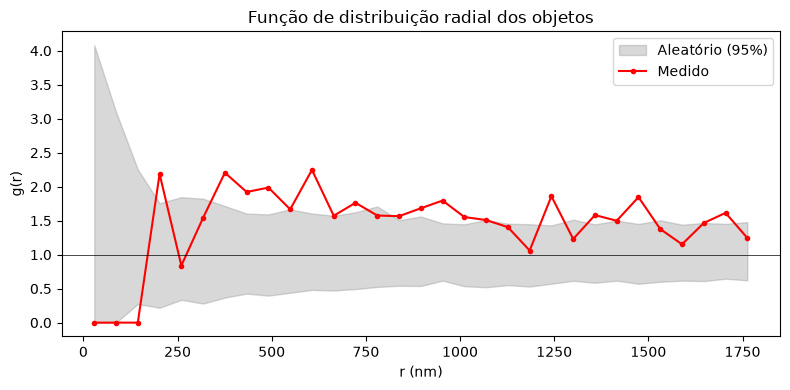

Há agregação (g(r) acima do envelope aleatório) em r entre 202.3 e 1705.0 nm


In [38]:
# Análise 2a - função de distribuição radial g(r) (análoga à integral radial do BVM)
# Referência: distribuição aleatória uniforme (CSR) na imagem inteira; g = 1 significa ausência de organização espacial.
# Objetos com tamanho finito não se sobrepõem, então g(r) fica abaixo de 1 para r menor que o diâmetro (esperado).

regiao = mascara_roi
dr = probe_semiangle / 2.0
bordas_r = np.arange(0, r_max_pares + dr, dr)
g, g_inf, g_sup = distribuicao_radial(pos_x, pos_y, regiao, bordas_r, n_sim=200)
r_centro = 0.5 * (bordas_r[:-1] + bordas_r[1:])

ymax = None     # limite superior do eixo y (opcional)
fig, eixo = plt.subplots(figsize=(8, 4))
eixo.fill_between(r_centro * fator_nm, g_inf, g_sup, color='gray', alpha=0.3, label='Aleatório (95%)')
eixo.plot(r_centro * fator_nm, g, 'r-o', markersize=3, label='Medido')
eixo.axhline(1, color='k', linewidth=0.5)
eixo.set_xlabel('r (' + unidade + ')'); eixo.set_ylabel('g(r)'); eixo.set_title('Função de distribuição radial dos objetos')
if ymax is not None:
    eixo.set_ylim(0, ymax)
eixo.legend(); plt.tight_layout(); plt.show()

agregado = g > g_sup
if agregado.any():
    print('Há agregação (g(r) acima do envelope aleatório) em r entre %.1f e %.1f %s' % (r_centro[agregado].min() * fator_nm, r_centro[agregado].max() * fator_nm, unidade))
else:
    print('Não há agregação significativa em relação a uma distribuição aleatória.')

Distância média ao vizinho mais próximo: 363.7 nm
Índice de Clark-Evans: R = 1.07 (z = 1.1) -> compatível com distribuição aleatória
Células de Voronoi inteiras: 37 | área média = 3.08e+05 nm² | coeficiente de variação = 0.72 (aleatório ≈ 0,53; rede regular ≈ 0)
Densidade média: 2.18 objetos/µm²


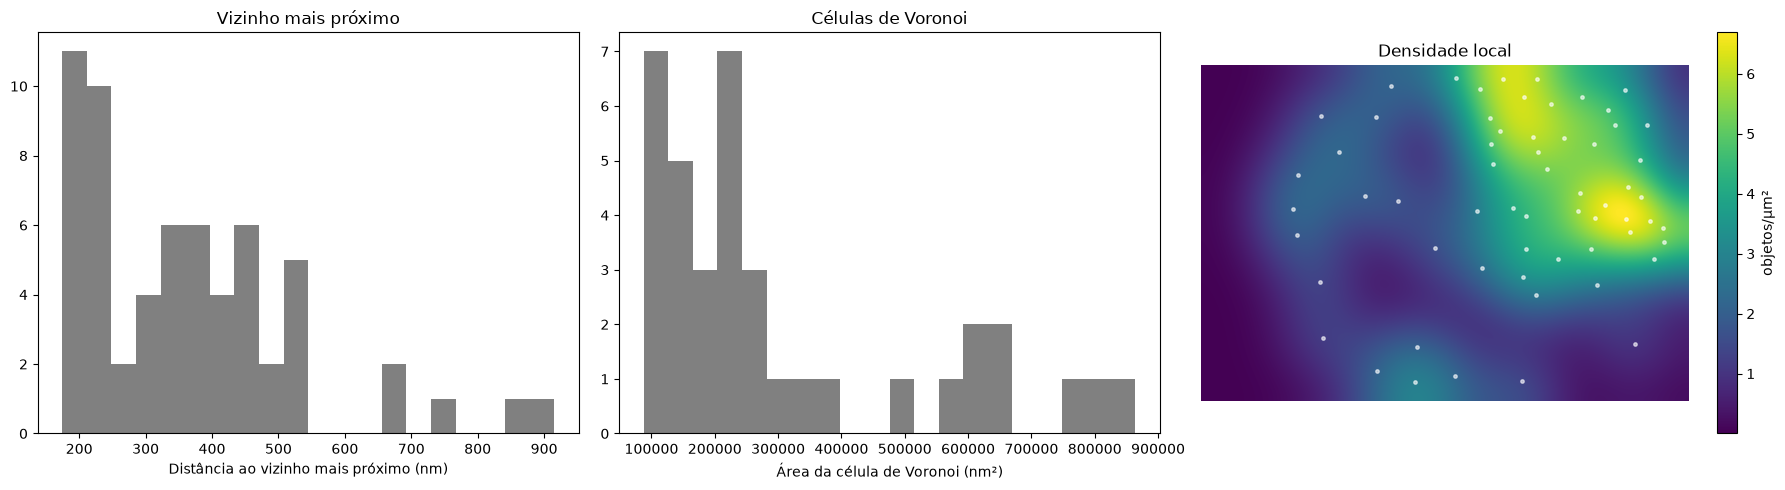

In [39]:
# Análise 2b - vizinho mais próximo, índice de Clark-Evans, células de Voronoi e densidade local

vizinho, R_ce, z_ce = indice_clark_evans(pos_x, pos_y, dataset.size)
print('Distância média ao vizinho mais próximo: %.1f %s' % (vizinho.mean() * fator_nm, unidade))
print('Índice de Clark-Evans: R = %.2f (z = %.1f) -> %s' % (R_ce, z_ce, 'agregado' if z_ce < -1.96 else ('ordenado/regular' if z_ce > 1.96 else 'compatível com distribuição aleatória')))

areas_vor, ids_vor = areas_de_voronoi(pos_x, pos_y, dataset.shape)
cv_vor = float(areas_vor.std() / areas_vor.mean()) if len(areas_vor) > 2 else float('nan')
print('Células de Voronoi inteiras: %d | área média = %.3g %s | coeficiente de variação = %.2f (aleatório ≈ 0,53; rede regular ≈ 0)' % (len(areas_vor), areas_vor.mean() * fator_nm ** 2, unidade_area, cv_vor))

dens = mapa_de_densidade(pos_x, pos_y, dataset.shape, sigma=4 * probe_semiangle)
fator_dens = 1.0 / (fator_nm ** 2) if unidade == 'nm' else 1.0
unidade_dens = 'objetos/µm²' if unidade == 'nm' else 'objetos/pixel²'
dens_plot = dens * (fator_dens * 1e6 if unidade == 'nm' else 1.0)
print('Densidade média: %.3g %s' % (len(pos_x) / area_imagem * (1e6 if unidade == 'nm' else 1.0), unidade_dens))

fig, eixos = plt.subplots(1, 3, figsize=(18, 5))
eixos[0].hist(vizinho * fator_nm, bins=20, color='gray'); eixos[0].set_xlabel('Distância ao vizinho mais próximo (' + unidade + ')'); eixos[0].set_title('Vizinho mais próximo')
eixos[1].hist(areas_vor * fator_nm ** 2, bins=20, color='gray'); eixos[1].set_xlabel('Área da célula de Voronoi (' + unidade_area + ')'); eixos[1].set_title('Células de Voronoi')
im = eixos[2].imshow(dens_plot, cmap='viridis'); plt.colorbar(im, ax=eixos[2], fraction=0.046, label=unidade_dens)
eixos[2].scatter(pos_x, pos_y, s=6, c='w', alpha=0.6); eixos[2].set_title('Densidade local'); eixos[2].axis('off')
plt.tight_layout(); plt.show()

# Mapeamento automatizado de orientação e morfologia (análogo ao ACOM)

In [40]:
# Cria um plano de orientação para os objetos: biblioteca de elipses (ângulo no plano x razão de aspecto)

plano_orientacao = {
    'angle_step_in_plane': 3,                       # passo angular da biblioteca (graus)
    'razoes': np.arange(1.0, 3.01, 0.1),            # razões de aspecto da biblioteca
    'n_max_objetos': 80,                            # os maiores objetos inteiros (limita o tempo de cálculo)
    'area_min_px': int(np.pi * (1.2 * probe_semiangle) ** 2),   # objetos menores têm poucos pixels para definir a orientação
}

# # Plano alternativo (faixa restrita de razões de aspecto, passo angular menor)
# plano_orientacao = {'angle_step_in_plane': 1, 'razoes': np.arange(1.0, 2.01, 0.05), 'n_max_objetos': 80, 'area_min_px': plano_orientacao['area_min_px']}

candidatos_ori = np.flatnonzero(internos & (objetos['area'] >= plano_orientacao['area_min_px']))
candidatos_ori = candidatos_ori[np.argsort(objetos['area'][candidatos_ori])[::-1]][:plano_orientacao['n_max_objetos']]
print('Objetos na análise de orientação:', len(candidatos_ori))

Objetos na análise de orientação: 23


Objeto 66: ângulo = 3°, razão de aspecto = 2.00, IoU = 0.827


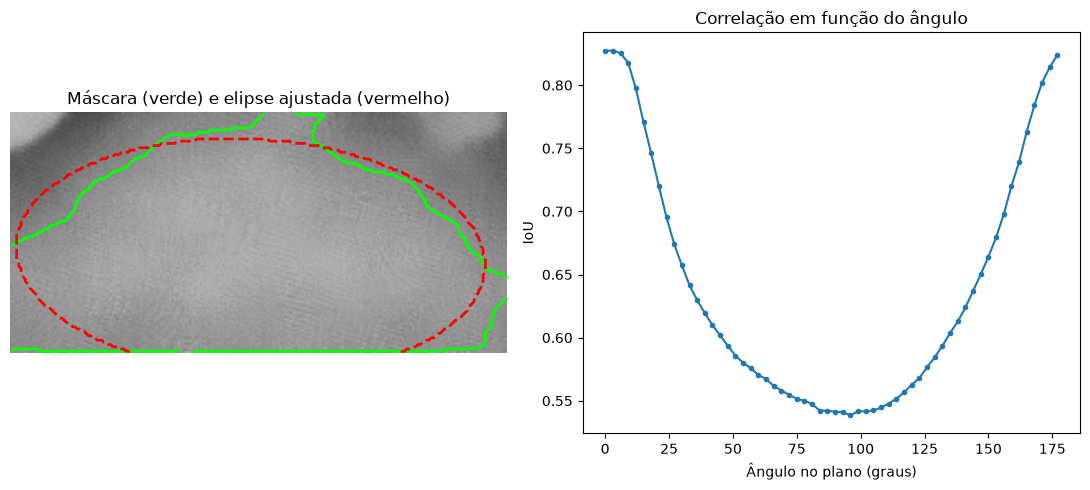

In [41]:
# Testa o casamento (matching) em um objeto: o mais alongado entre os candidatos
k_teste = candidatos_ori[int(np.argmax(objetos['razao_aspecto'][candidatos_ori]))]
id_teste = int(objetos['id'][k_teste])
mascara_p = rotulos == id_teste
ys_p, xs_p = np.nonzero(mascara_p)
caixa = (slice(ys_p.min(), ys_p.max() + 1), slice(xs_p.min(), xs_p.max() + 1))

orientation = casar_elipse(
    mascara_p[caixa],
    passo_angulo = plano_orientacao['angle_step_in_plane'],
    razoes = plano_orientacao['razoes'],
)
ang_ajuste, razao_ajuste, iou_ajuste, curva_iou, angulos_lib = orientation
print('Objeto %d: ângulo = %.0f°, razão de aspecto = %.2f, IoU = %.3f' % (id_teste, np.rad2deg(ang_ajuste), razao_ajuste, iou_ajuste))

# plota as comparações
m_crop = mascara_p[caixa]
cy_p, cx_p = ndimage.center_of_mass(m_crop)
elipse_ajustada = elipse_por_area(m_crop.shape, (cx_p, cy_p), float(m_crop.sum()), razao_ajuste, ang_ajuste)

fig, eixos = plt.subplots(1, 2, figsize=(11, 5))
eixos[0].imshow(dataset_visual[caixa], cmap='gray', vmin=0, vmax=1)
eixos[0].contour(m_crop, levels=[0.5], colors='lime', linewidths=2)
eixos[0].contour(elipse_ajustada, levels=[0.5], colors='r', linewidths=2, linestyles='--')
eixos[0].set_title('Máscara (verde) e elipse ajustada (vermelho)'); eixos[0].axis('off')
eixos[1].plot(np.rad2deg(angulos_lib), curva_iou, 'o-', markersize=3)
eixos[1].set_xlabel('Ângulo no plano (graus)'); eixos[1].set_ylabel('IoU'); eixos[1].set_title('Correlação em função do ângulo')
plt.tight_layout(); plt.show()

In [42]:
# Ajusta a orientação em todos os objetos selecionados
orientation_map = SimpleNamespace(
    angulo=np.full(rotulos.shape, np.nan, dtype=np.float32),
    razao=np.full(rotulos.shape, np.nan, dtype=np.float32),
    corr=np.full(rotulos.shape, np.nan, dtype=np.float32),
    tabela=[],
)
for k in candidatos_ori:
    i = int(objetos['id'][k])
    mascara_i = rotulos == i
    ys_i, xs_i = np.nonzero(mascara_i)
    ang_i, raz_i, iou_i, _, _ = casar_elipse(
        mascara_i[ys_i.min():ys_i.max() + 1, xs_i.min():xs_i.max() + 1],
        passo_angulo = plano_orientacao['angle_step_in_plane'],
        razoes = plano_orientacao['razoes'],
    )
    # Objetos quase circulares (razão de aspecto < 1,1) não têm orientação definida: ficam sem ângulo
    orientacao_definida = raz_i >= 1.1
    orientation_map.angulo[mascara_i] = ang_i if orientacao_definida else np.nan
    orientation_map.razao[mascara_i] = raz_i
    orientation_map.corr[mascara_i] = iou_i
    orientation_map.tabela.append((i, float(xs_i.mean()), float(ys_i.mean()), float(mascara_i.sum()), np.rad2deg(ang_i) if orientacao_definida else np.nan, raz_i, iou_i))

tabela_ori = np.array(orientation_map.tabela, dtype=float)
print('Objetos ajustados: %d (%d com orientação definida) | IoU médio = %.3f | razão de aspecto média = %.2f' % (len(tabela_ori), np.sum(~np.isnan(tabela_ori[:, 4])), tabela_ori[:, 6].mean(), tabela_ori[:, 5].mean()))

Objetos ajustados: 23 (19 com orientação definida) | IoU médio = 0.896 | razão de aspecto média = 1.37


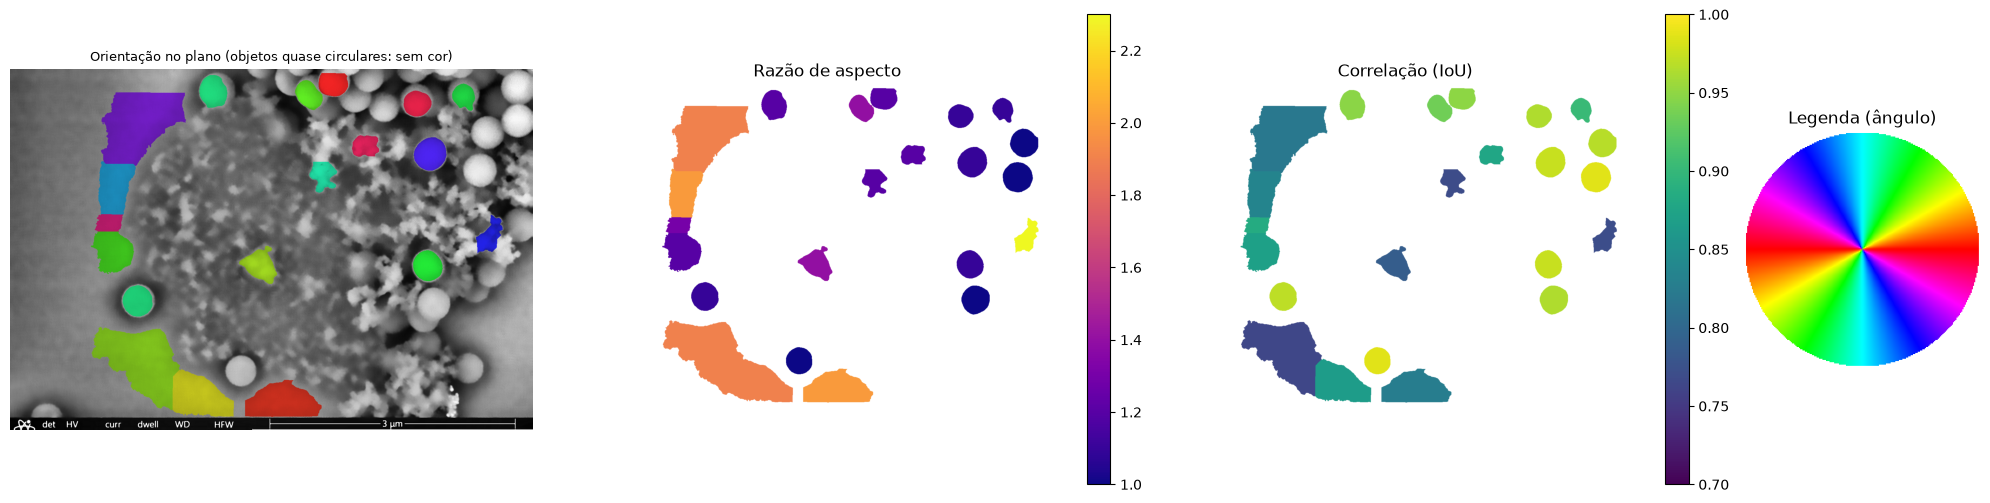

In [43]:
# Plota os mapas de orientação
corr_range = [0.7, 1.0]

fig, eixos = plt.subplots(1, 4, figsize=(20, 5), gridspec_kw={'width_ratios': [1, 1, 1, 0.45]})
fundo_cinza = dataset_visual
tem_ori = ~np.isnan(orientation_map.angulo)
hue = (np.nan_to_num(orientation_map.angulo) % np.pi) / np.pi
cor_ori = hsv_to_rgb(np.dstack([hue, np.full_like(hue, 0.85), 0.35 + 0.65 * fundo_cinza]))
cor_ori[~tem_ori] = np.dstack([fundo_cinza] * 3)[~tem_ori]
eixos[0].imshow(cor_ori); eixos[0].set_title('Orientação no plano (objetos quase circulares: sem cor)', fontsize=9)
im1 = eixos[1].imshow(orientation_map.razao, cmap='plasma'); eixos[1].set_title('Razão de aspecto')
plt.colorbar(im1, ax=eixos[1], fraction=0.046, pad=0.04)
im2 = eixos[2].imshow(orientation_map.corr, cmap='viridis', vmin=corr_range[0], vmax=corr_range[1]); eixos[2].set_title('Correlação (IoU)')
plt.colorbar(im2, ax=eixos[2], fraction=0.046, pad=0.04)
for e in eixos[:3]: e.axis('off')
eixos[3].imshow(roda_de_cores_orientacao()); eixos[3].set_title('Legenda (ângulo)'); eixos[3].axis('off')
plt.tight_layout(); plt.show()

In [44]:
# # Plota os mapas de orientação (alternativa: ângulo em escala de cinza)
# plt.figure(figsize=(8, 8))
# plt.imshow(np.rad2deg(orientation_map.angulo), cmap='twilight')
# plt.colorbar(label='Ângulo (graus)')
# plt.title('Orientação no plano')

# Mapas do tensor de estrutura e orientação dominante (análogos aos mapas de deformação)

In [45]:
# Tensor de estrutura local: componentes normalizadas (exx, eyy, exy) e orientação dominante das bordas (theta)

sigma_grad = 2.0         # pixels (escala do gradiente)
sigma_int = 12.0         # pixels (escala da média local)
ts = tensor_de_estrutura(linear, sigma_grad, sigma_int)

# Só mostra onde há energia de gradiente (bordas e estruturas)
mask = (ts['energia'] > np.percentile(ts['energia'][mascara_roi], 70)) & mascara_roi

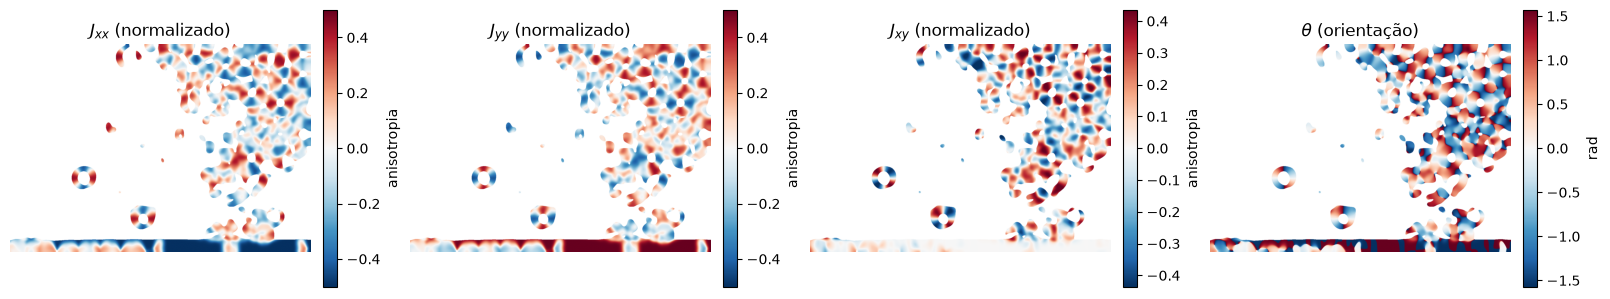

In [46]:
labels = ["exx", "eyy", "exy", "theta"]
titles = [r"$J_{xx}$ (normalizado)", r"$J_{yy}$ (normalizado)", r"$J_{xy}$ (normalizado)", r"$\theta$ (orientação)"]

fig, axs = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)

for ax, label, title in zip(axs, labels, titles):
    imdata = ts[label].copy()
    imdata[~mask] = np.nan

    if label == "theta":
        v = np.pi / 2
        unit = "rad"
    else:
        v = np.nanpercentile(np.abs(imdata), 99)
        unit = "anisotropia"

    im = ax.imshow(imdata, cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(title)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=unit)

plt.show()

Orientação dominante das estruturas: 180° (a partir do eixo x, sentido horário) | parâmetro de ordem S = 0.57 (0 = isotrópico, 1 = alinhado)
Coerência média local: 0.56


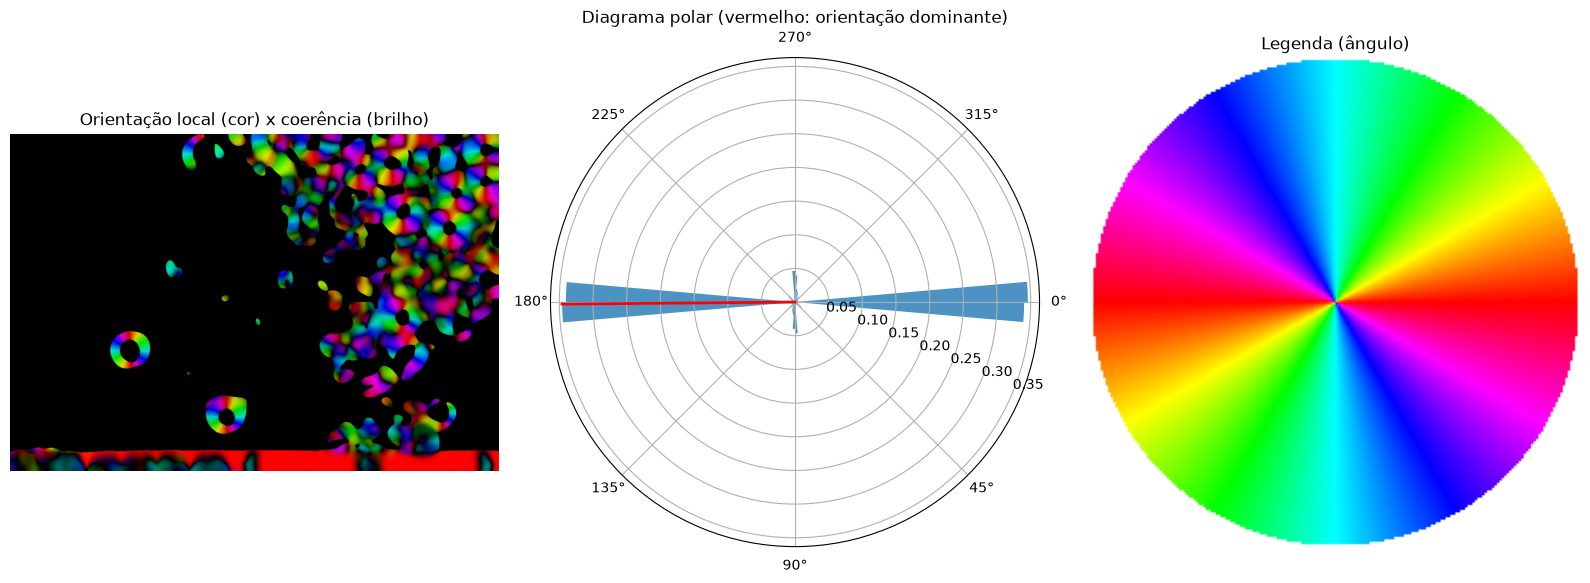

In [47]:
# Análise 3 - orientação dominante, parâmetro de ordem e diagrama polar das estruturas alinhadas (estrias, fibras, lamelas)

# ROI da análise de orientação: (linha_min, linha_max, coluna_min, coluna_max). None = imagem inteira
ROI_orientacao = None

regiao_ori = mask.copy()
if ROI_orientacao is not None:
    r0, r1, c0, c1 = ROI_orientacao
    limite = np.zeros_like(mask); limite[r0:r1, c0:c1] = True
    regiao_ori &= limite

theta_estrutura = ts['theta'] + np.pi / 2          # as linhas da estrutura são perpendiculares ao gradiente
peso_ori = (ts['energia'] * ts['coerencia'])[regiao_ori]
ang_dom, S_ordem = orientacao_dominante(theta_estrutura[regiao_ori], peso_ori)
print('Orientação dominante das estruturas: %.0f° (a partir do eixo x, sentido horário) | parâmetro de ordem S = %.2f (0 = isotrópico, 1 = alinhado)' % (ang_dom, S_ordem))
print('Coerência média local: %.2f' % ts['coerencia'][regiao_ori].mean())

centros_graus, densidade_ori = histograma_orientacao(theta_estrutura[regiao_ori], peso_ori)
fig = plt.figure(figsize=(16, 5.5))
ax0 = fig.add_subplot(1, 3, 1)
hue_t = (theta_estrutura % np.pi) / np.pi
cor_t = hsv_to_rgb(np.dstack([hue_t, np.ones_like(hue_t), np.clip(ts['coerencia'], 0, 1)]))
cor_t[~regiao_ori] = 0
ax0.imshow(cor_t); ax0.set_title('Orientação local (cor) x coerência (brilho)'); ax0.axis('off')
ax1 = fig.add_subplot(1, 3, 2, projection='polar')
ang_rad = np.deg2rad(np.concatenate([centros_graus, centros_graus + 180]))
ax1.bar(ang_rad, np.concatenate([densidade_ori, densidade_ori]), width=np.deg2rad(5), color='tab:blue', alpha=0.8)
ax1.plot([np.deg2rad(ang_dom)] * 2, [0, densidade_ori.max()], 'r-', linewidth=2)
ax1.set_theta_direction(-1); ax1.set_title('Diagrama polar (vermelho: orientação dominante)')
ax2 = fig.add_subplot(1, 3, 3)
ax2.imshow(roda_de_cores_orientacao()); ax2.set_title('Legenda (ângulo)'); ax2.axis('off')
plt.tight_layout(); plt.show()

# Fases, textura e qualidade

Fase 1: 10.2% da área
Fase 2: 61.8% da área
Fase 3: 27.9% da área


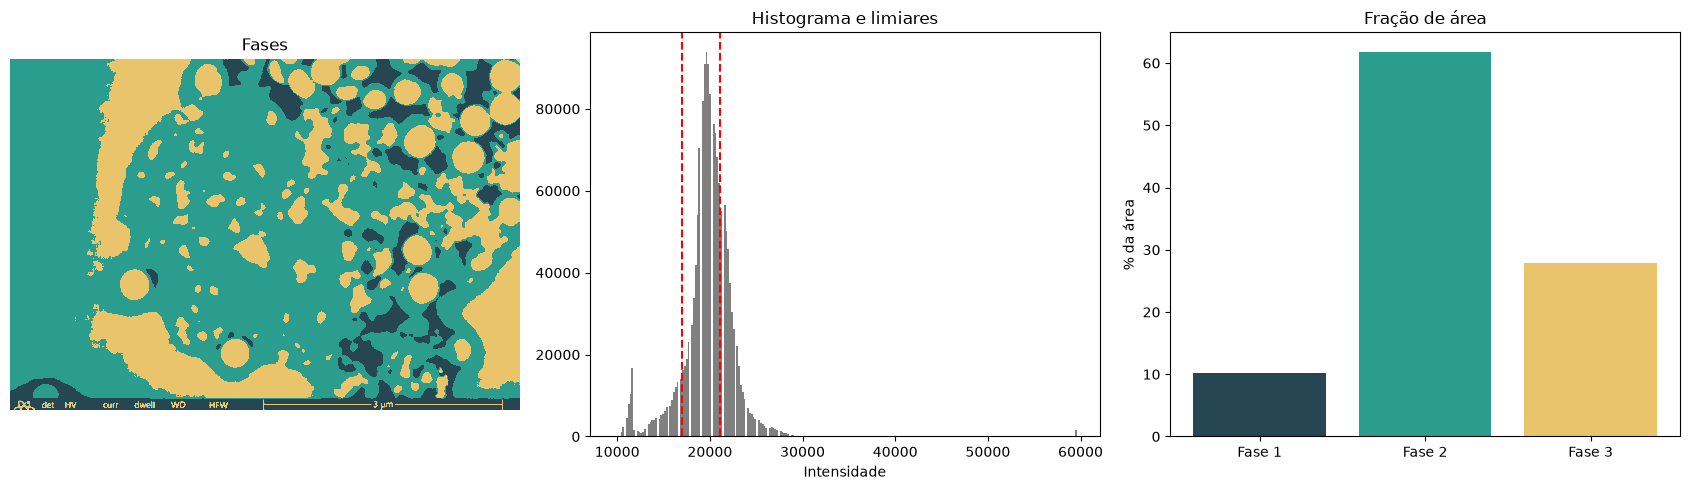

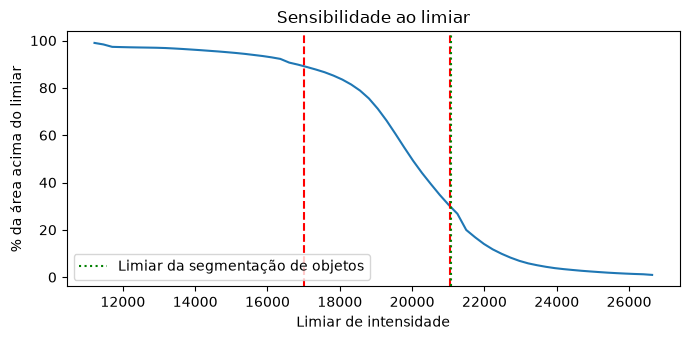

In [48]:
# Análise 4 - fases por níveis de cinza (multi-Otsu), frações de área e sensibilidade ao limiar
from matplotlib.colors import ListedColormap

n_fases = 3
rotulos_fases, limiares_fases, fracoes_fases = segmentar_fases(linear, mascara_roi, n_fases)
cores_fases = ['#264653', '#2a9d8f', '#e9c46a', '#f4a261', '#e76f51'][:n_fases]
for k in range(n_fases):
    print('Fase %d: %.1f%% da área' % (k + 1, 100 * fracoes_fases[k]))

fig, eixos = plt.subplots(1, 3, figsize=(17, 5))
eixos[0].imshow(rotulos_fases, cmap=ListedColormap(cores_fases), interpolation='nearest'); eixos[0].set_title('Fases'); eixos[0].axis('off')
eixos[1].hist(linear.ravel(), bins=256, color='gray')
for t in limiares_fases:
    eixos[1].axvline(t, color='r', linestyle='--')
eixos[1].set_title('Histograma e limiares'); eixos[1].set_xlabel('Intensidade')
eixos[2].bar(['Fase %d' % (k + 1) for k in range(n_fases)], 100 * np.array(fracoes_fases), color=cores_fases)
eixos[2].set_ylabel('% da área'); eixos[2].set_title('Fração de área')
plt.tight_layout(); plt.show()

limiares_curva, fracao_curva = curva_fracao_vs_limiar(linear, mascara_roi)
plt.figure(figsize=(7, 3.5))
plt.plot(limiares_curva, 100 * fracao_curva)
for t in limiares_fases:
    plt.axvline(t, color='r', linestyle='--')
plt.axvline(limiar_seg if np.isscalar(limiar_seg) else np.median(limiar_seg), color='g', linestyle=':', label='Limiar da segmentação de objetos')
plt.xlabel('Limiar de intensidade'); plt.ylabel('% da área acima do limiar'); plt.title('Sensibilidade ao limiar'); plt.legend()
plt.tight_layout(); plt.show()

Região      Contraste    Dissimilar.    Homogeneid.    Energia   Correlação
Objetos         8.735          2.086          0.403      0.182        0.010
Fundo           6.337          1.624          0.477      0.211        0.240
Rugosidade média: objetos = 0.0742 | fundo = 0.0554


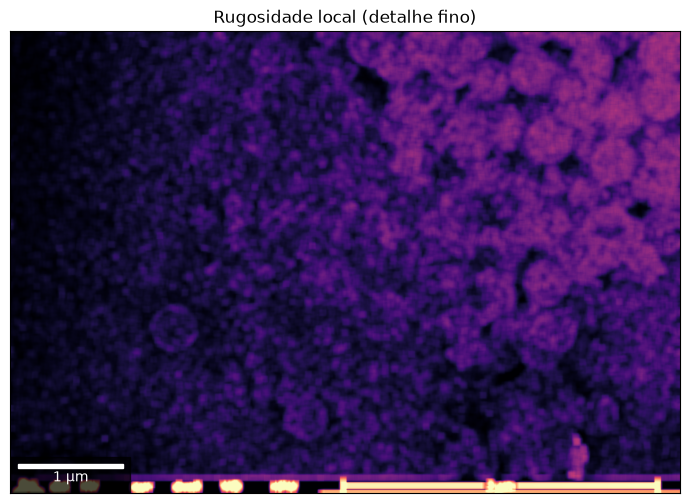

Comprimento de correlação (diâmetro equivalente onde a ACF cai a 1/e): 195.3 nm
Eixos da elipse de correlação: 176.0 e 222.0 nm | anisotropia = 1.26 | eixo maior a 179° do eixo x


In [49]:
# Análise 5 - textura (GLCM) dos objetos e do fundo, rugosidade local e comprimento de correlação

# Textura em blocos de 32 x 32 pixels inteiramente dentro de cada região
print('%-10s %10s %14s %14s %10s %12s' % ('Região', 'Contraste', 'Dissimilar.', 'Homogeneid.', 'Energia', 'Correlação'))
texturas = {}
for nome_r, mascara_r in (('Objetos', ndimage.binary_erosion(binaria, iterations=2)), ('Fundo', ndimage.binary_erosion(~binaria, iterations=2))):
    t = textura_por_regiao(dataset_denoised, mascara_r)
    texturas[nome_r] = t
    if t is None:
        print('%-10s sem blocos de 32 x 32 pixels totalmente dentro da região' % nome_r)
    else:
        print('%-10s %10.3f %14.3f %14.3f %10.3f %12.3f' % (nome_r, t['contrast'], t['dissimilarity'], t['homogeneity'], t['energy'], t['correlation']))

rugosidade = mapa_rugosidade_local(dataset_denoised, sigma_passa_alta=3.0, janela=15)
print('Rugosidade média: objetos = %.4f | fundo = %.4f' % (rugosidade[binaria].mean() if binaria.any() else float('nan'), rugosidade[~binaria].mean() if (~binaria).any() else float('nan')))
mostrar_imagens([rugosidade], ['Rugosidade local (detalhe fino)'], cmaps=['magma'], pixel_nm=tamanho_pixel_roi, tamanho=7)

# Autocorrelação 2D: comprimento de correlação e anisotropia (imagem sem ruído)
res_acf = autocorrelacao_2d(dataset_denoised)
print('Comprimento de correlação (diâmetro equivalente onde a ACF cai a 1/e): %.1f %s' % (res_acf['diametro_eq'] * fator_nm, unidade))
print('Eixos da elipse de correlação: %.1f e %.1f %s | anisotropia = %.2f | eixo maior a %.0f° do eixo x' % (res_acf['eixos'][0] * fator_nm, res_acf['eixos'][1] * fator_nm, unidade, res_acf['anisotropia'], res_acf['angulo']))

In [50]:
# Análise 6 - tabela de qualidade das versões da imagem (independente da escala de brilho)

versoes = {
    'Original (analisada)': imagem_original_roi,
    'Corrigida': dataset,
    'Sem ruído (NLM)': dataset_denoised,
    'SCIENTIFIC final': dataset_scientific,
    'VISUAL final': dataset_visual,
}
metricas_versoes = {nome: metricas_qualidade(img) for nome, img in versoes.items()}
imprimir_tabela_metricas(metricas_versoes)

Versão                          Ruído   SNR (dB)   Nitidez rel.   Entropia  Contraste
Original (analisada)           0.1095       3.38          0.182      5.925      0.162
Corrigida                      0.1112       1.49          0.244      7.461      0.132
Sem ruído (NLM)                0.0485       8.86          0.231      6.972      0.135
SCIENTIFIC final               0.0799       5.31          0.260      7.502      0.147
VISUAL final                   0.0152      21.57          0.205      7.532      0.182
Obs.: filtros mais agressivos aumentam o SNR à custa de detalhes; interprete o SNR junto com a nitidez relativa (borda forte / contraste).


# Salvamento dos resultados

In [51]:
# Salva tabelas (CSV) e imagens na pasta do notebook

base = os.path.splitext(filename)[0] + '_SAIDA_'

# Tabela de todos os objetos segmentados
colunas = ['id', 'x_px', 'y_px', 'area_' + unidade_area, 'diametro_eq_' + unidade, 'circularidade', 'razao_aspecto', 'orientacao_graus', 'solidez', 'intensidade_media', 'toca_borda']
with open(base + 'OBJETOS.csv', 'w', newline='', encoding='utf-8') as f:
    escritor = csv.writer(f)
    escritor.writerow(colunas)
    for k in range(n_obj):
        escritor.writerow([int(objetos['id'][k]), objetos['x'][k], objetos['y'][k], objetos['area'][k] * fator_nm ** 2, objetos['diam_eq'][k] * fator_nm,
                           objetos['circularidade'][k], objetos['razao_aspecto'][k], objetos['orientacao'][k], objetos['solidez'][k], objetos['intensidade'][k], int(objetos['toca_borda'][k])])

# Tabela do ajuste de elipses (orientação)
with open(base + 'ORIENTACAO_ELIPSES.csv', 'w', newline='', encoding='utf-8') as f:
    escritor = csv.writer(f)
    escritor.writerow(['id', 'x_px', 'y_px', 'area_px', 'angulo_graus', 'razao_aspecto', 'iou'])
    escritor.writerows(orientation_map.tabela)

# Resumo das análises
with open(base + 'RESUMO_ANALISES.csv', 'w', newline='', encoding='utf-8') as f:
    escritor = csv.writer(f)
    escritor.writerow(['grandeza', 'valor', 'unidade'])
    escritor.writerow(['objetos_segmentados', n_obj, ''])
    escritor.writerow(['fracao_de_area_dos_objetos', cobertura, 'fracao'])
    for nome_e in ('media', 'desvio', 'D10', 'D50', 'D90', 'amplitude_rel'):
        escritor.writerow(['diametro_eq_' + nome_e, est[nome_e], unidade if nome_e != 'amplitude_rel' else ''])
    escritor.writerow(['clark_evans_R', R_ce, ''])
    escritor.writerow(['clark_evans_z', z_ce, ''])
    escritor.writerow(['voronoi_coef_variacao', cv_vor, ''])
    escritor.writerow(['orientacao_dominante', ang_dom, 'graus'])
    escritor.writerow(['parametro_de_ordem_S', S_ordem, ''])
    escritor.writerow(['comprimento_correlacao', res_acf['diametro_eq'] * fator_nm, unidade])
    escritor.writerow(['anisotropia_correlacao', res_acf['anisotropia'], ''])
    for k in range(n_fases):
        escritor.writerow(['fracao_area_fase_%d' % (k + 1), fracoes_fases[k], 'fracao'])

imagens_saida = {
    'PLUS_SCIENTIFIC.tif': dataset_scientific.astype(np.float32),
    'PLUS_VISUAL.tif': dataset_visual.astype(np.float32),
    'ROTULOS.tif': rotulos.astype(np.int32),
    'DENSIDADE_LOCAL.tif': dens.astype(np.float32),
    'ORIENTACAO_LOCAL.tif': theta_estrutura.astype(np.float32),
    'COERENCIA.tif': ts['coerencia'].astype(np.float32),
    'RUGOSIDADE_LOCAL.tif': rugosidade.astype(np.float32),
    'FASES.tif': rotulos_fases,
}
for sufixo, imagem_saida in imagens_saida.items():
    tifffile.imwrite(base + sufixo, imagem_saida, photometric='minisblack')

print('ARQUIVOS SALVOS em', pasta_notebook)
for sufixo in ['OBJETOS.csv', 'ORIENTACAO_ELIPSES.csv', 'RESUMO_ANALISES.csv'] + list(imagens_saida):
    print(os.path.basename(base) + sufixo)

ARQUIVOS SALVOS em C:\JupyterLab\2-semestre\IP1\SEM
MEV-NC_AM_BSE_005_SAIDA_OBJETOS.csv
MEV-NC_AM_BSE_005_SAIDA_ORIENTACAO_ELIPSES.csv
MEV-NC_AM_BSE_005_SAIDA_RESUMO_ANALISES.csv
MEV-NC_AM_BSE_005_SAIDA_PLUS_SCIENTIFIC.tif
MEV-NC_AM_BSE_005_SAIDA_PLUS_VISUAL.tif
MEV-NC_AM_BSE_005_SAIDA_ROTULOS.tif
MEV-NC_AM_BSE_005_SAIDA_DENSIDADE_LOCAL.tif
MEV-NC_AM_BSE_005_SAIDA_ORIENTACAO_LOCAL.tif
MEV-NC_AM_BSE_005_SAIDA_COERENCIA.tif
MEV-NC_AM_BSE_005_SAIDA_RUGOSIDADE_LOCAL.tif
MEV-NC_AM_BSE_005_SAIDA_FASES.tif
